In [ ]:
import torch
print("Torch version :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
else:
    print("No GPU detected -> Runtime > Change runtime type > GPU")

Torch version : 2.11.0+cu128
CUDA disponible : True
GPU : Tesla T4


In [ ]:
!pip install -q pycocotools albumentations opencv-python-headless matplotlib pandas scikit-learn
print("Dependencies installed.")

Dependencies installed.


In [ ]:
import os, json, random, copy
from pathlib import Path
from collections import defaultdict

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import torch
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

from pycocotools.coco import COCO
from pycocotools import mask as maskUtils
import albumentations as A

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print("Imports OK | device =", device)

Imports OK | device = cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

CKPT_DIR = Path('/content/drive/MyDrive/spinal_AI_v6/checkpoints')
CKPT_DIR.mkdir(parents=True, exist_ok=True)

LATEST_CKPT = CKPT_DIR / 'checkpoint_latest.pth'
BEST_CKPT = CKPT_DIR / 'checkpoint_best.pth'

print("Checkpoints ->", CKPT_DIR)
print("Reprise possible :", LATEST_CKPT.exists())

In [ ]:
%cd /content
!rm -rf Spinal-AI2024
!git clone https://github.com/Ernestchenchen/Spinal-AI2024.git

/content
Cloning into 'Spinal-AI2024'...
remote: Enumerating objects: 20090, done.
remote: Counting objects: 100% (30/30), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 20090 (delta 20), reused 4 (delta 4), pack-reused 20060 (from 1)
Receiving objects: 100% (20090/20090), 515.03 MiB | 19.61 MiB/s, done.
Resolving deltas: 100% (34/34), done.
Updating files: 100% (20008/20008), done.


In [ ]:
DATASET_ROOT = Path("/content/Spinal-AI2024")
assert DATASET_ROOT.exists(), "Le dossier n'existe pas."
print("Racine :", DATASET_ROOT)
for item in sorted(DATASET_ROOT.iterdir()):
    print("  ", item.name)

Racine : /content/Spinal-AI2024
   .git
   .gitignore
   Cobb_spinal-AI2024-test_gt.txt
   Cobb_spinal-AI2024-train_gt.txt
   README.md
   Spinal-AI2024-subset1
   Spinal-AI2024-subset2
   Spinal-AI2024-subset3
   Spinal-AI2024-subset4
   Spinal-AI2024-subset5
   Spinal_AI2024_test_annotation.zip
   Spinal_AI2024_train__annotation.zip
   figs
   image_similarity_checklist.xlsx


In [ ]:
import zipfile

def safe_extract(zip_path, out_dir):
    out_dir = Path(out_dir)
    if zip_path.exists() and not out_dir.exists():
        out_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_path, "r") as z:
            z.extractall(out_dir)
        print("Extracted:", out_dir)
    else:
        print("Already extracted or ZIP missing:", out_dir)

safe_extract(DATASET_ROOT / "Spinal_AI2024_train__annotation.zip", DATASET_ROOT / "train_annotations")
safe_extract(DATASET_ROOT / "Spinal_AI2024_test_annotation.zip",  DATASET_ROOT / "test_annotations")

Extracted: /content/Spinal-AI2024/train_annotations
Extracted: /content/Spinal-AI2024/test_annotations


In [ ]:
json_files = list(DATASET_ROOT.rglob("*.json"))
TRAIN_JSON = next((p for p in json_files if "train" in p.name.lower()), None)
TEST_JSON  = next((p for p in json_files if "test"  in p.name.lower()), None)
print("TRAIN_JSON:", TRAIN_JSON)
print("TEST_JSON :", TEST_JSON)
assert TRAIN_JSON and TEST_JSON, "train/test JSON not found."

TRAIN_JSON: /content/Spinal-AI2024/train_annotations/Spinal_AI2024_train__annotation.json
TEST_JSON : /content/Spinal-AI2024/test_annotations/Spinal_AI2024_test_annotation.json


In [ ]:
with open(TRAIN_JSON) as f:
    train_data = json.load(f)
print("Keys:", list(train_data.keys()))
print("Images :", len(train_data["images"]))
print("Annotations :", len(train_data["annotations"]))
print("Categories :", len(train_data["categories"]))

Keys: ['images', 'annotations', 'categories']
Images : 16000
Annotations : 273450
Categories : 1


In [ ]:
print("All the categories in the JSON:")
for c in train_data["categories"]:
    print(f"  id={c['id']} | name={c['name']} | supercategory={c['supercategory']}")

CATEGORY_REMAP = {c["id"]: 1 for c in train_data["categories"]}
CLASS_NAMES = {0: "background", 1: "vertebra"}
print(f"\nCATEGORY_REMAP : {len(CATEGORY_REMAP)} catégories -> toutes mappées vers classe 1")
print("CLASS_NAMES :", CLASS_NAMES)

All the categories in the JSON:
  id=1 | name=text | supercategory=text

CATEGORY_REMAP : 1 catégories -> toutes mappées vers classe 1
CLASS_NAMES : {0: 'background', 1: 'vertebra'}


In [ ]:
images_by_id = {img["id"]: img for img in train_data["images"]}
anns_by_image = defaultdict(list)
for ann in train_data["annotations"]:
    anns_by_image[ann["image_id"]].append(ann)
print("Indexed images :", len(images_by_id))
print("Images with annotations:", len(anns_by_image))

Indexed images : 16000
Images with annotations: 15999


In [ ]:
IMAGE_DIRS = [DATASET_ROOT / f"Spinal-AI2024-subset{i}" for i in range(1, 6)]

def find_image_path(file_name):
    for d in IMAGE_DIRS:
        p = d / file_name
        if p.exists():
            return p
    return None

def coco_annotation_to_mask(ann, height, width):
    seg = ann["segmentation"]
    if isinstance(seg, list):  # polygones
        rles = maskUtils.frPyObjects(seg, height, width)
        rle = maskUtils.merge(rles)
    elif isinstance(seg, dict) and isinstance(seg.get("counts"), list):  # RLE non compressé
        rle = maskUtils.frPyObjects(seg, height, width)
    else:  # RLE compressé
        rle = seg
    m = maskUtils.decode(rle)
    if m.ndim == 3:
        m = np.any(m, axis=2)
    return m.astype(np.uint8)

_id   = next(iter(anns_by_image))
_info = images_by_id[_id]
_p    = find_image_path(_info["file_name"])
_m    = coco_annotation_to_mask(anns_by_image[_id][0], _info["height"], _info["width"])
print("Test path:", _p)
print("Test mask:", _m.shape, "unique values:", np.unique(_m))

Test path: /content/Spinal-AI2024/Spinal-AI2024-subset1/000001.jpg
Test mask: (512, 512) unique values: [0 1]


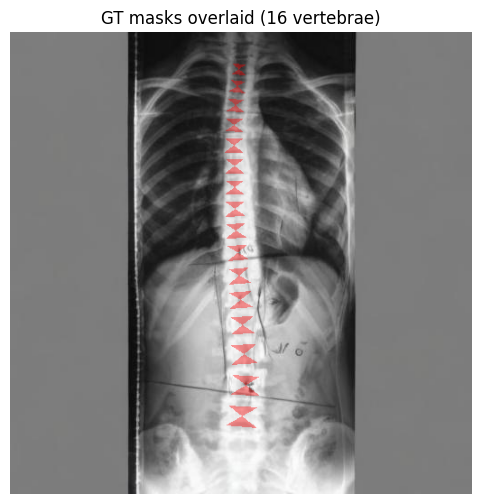

In [ ]:
sid  = _id
info = images_by_id[sid]
img = cv2.cvtColor(cv2.imread(str(find_image_path(info["file_name"]))), cv2.COLOR_BGR2RGB)
overlay = img.copy()
for ann in anns_by_image[sid]:
    m = coco_annotation_to_mask(ann, info["height"], info["width"])
    overlay[m == 1] = (0.6 * overlay[m == 1] + 0.4 * np.array([255, 0, 0])).astype(np.uint8)

plt.figure(figsize=(6, 6))
plt.imshow(overlay); plt.axis("off")
plt.title(f"GT masks overlaid ({len(anns_by_image[sid])} vertebrae)")
plt.show()

In [ ]:
import albumentations as A
import cv2

train_transform = A.Compose([
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.3),
    A.Affine(
        translate_percent={"x": (-0.05, 0.05), "y": (-0.05, 0.05)},
        scale=(0.95, 1.05),
        rotate=(-8, 8),
        border_mode=cv2.BORDER_CONSTANT,
        fill=0,
        p=0.5
    ),
    A.GaussNoise(p=0.2),
])
val_transform = None
print("Augmentation pipelines OK (Affine instead of deprecated ShiftScaleRotate).")

Augmentation pipelines OK (Affine instead of deprecated ShiftScaleRotate).


In [ ]:
class SpineSegmentationDataset(Dataset):
    def __init__(self, image_ids, images_by_id, anns_by_image, image_dirs, transform=None):
        self.image_ids    = list(image_ids)
        self.images_by_id = images_by_id
        self.anns_by_image = anns_by_image
        self.image_dirs   = image_dirs
        self.transform    = transform

    def __len__(self):
        return len(self.image_ids)

    def _find_path(self, file_name):
        for d in self.image_dirs:
            p = d / file_name
            if p.exists():
                return p
        return None

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        info = self.images_by_id[image_id]
        H, W = info["height"], info["width"]
        path = self._find_path(info["file_name"])
        if path is None:
            img = np.zeros((H, W, 3), dtype=np.uint8)
        else:
            raw = cv2.imread(str(path))
            img = np.zeros((H, W, 3), dtype=np.uint8) if raw is None \
                  else cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)

        masks = []
        for ann in self.anns_by_image.get(image_id, []):
            m = coco_annotation_to_mask(ann, H, W)
            if m.sum() > 0:
                masks.append(m)

        if self.transform is not None and len(masks) > 0:
            aug = self.transform(image=img, masks=masks)
            img, masks = aug["image"], aug["masks"]

        boxes, kept = [], []
        for m in masks:
            m = np.asarray(m)
            ys, xs = np.where(m > 0)
            if xs.size == 0 or ys.size == 0:
                continue
            x1, x2, y1, y2 = xs.min(), xs.max(), ys.min(), ys.max()
            if x2 > x1 and y2 > y1:
                boxes.append([float(x1), float(y1), float(x2), float(y2)])
                kept.append(m.astype(np.uint8))


        is_dummy = False
        if len(boxes) == 0:
            dummy = np.zeros((H, W), dtype=np.uint8)
            dummy[0:2, 0:2] = 1
            boxes, kept = [[0.0, 0.0, 1.0, 1.0]], [dummy]
            is_dummy = True

        boxes   = torch.as_tensor(boxes, dtype=torch.float32)
        masks_t = torch.as_tensor(np.stack(kept), dtype=torch.uint8)
        labels  = torch.ones((len(boxes),), dtype=torch.int64)
        area    = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])

        image_tensor = torch.from_numpy(img.transpose(2, 0, 1)).float() / 255.0

        target = {
            "boxes": boxes,
            "labels": labels,
            "masks": masks_t,
            "image_id": torch.tensor([image_id]),
            "area": area,
            "iscrowd": torch.zeros((len(boxes),), dtype=torch.int64),
            "is_dummy": torch.tensor([is_dummy]),
        }
        return image_tensor, target

print("SpineSegmentationDataset defined (avec flag is_dummy).")

SpineSegmentationDataset defined (avec flag is_dummy).


In [ ]:
all_ids = list(anns_by_image.keys())
random.Random(SEED).shuffle(all_ids)
split = int(0.9 * len(all_ids))
train_ids, val_ids = all_ids[:split], all_ids[split:]

train_dataset = SpineSegmentationDataset(train_ids, images_by_id, anns_by_image, IMAGE_DIRS, transform=train_transform)
val_dataset   = SpineSegmentationDataset(val_ids,   images_by_id, anns_by_image, IMAGE_DIRS, transform=val_transform)

with open(TEST_JSON) as f:
    test_data = json.load(f)
test_images_by_id = {img["id"]: img for img in test_data["images"]}
test_anns_by_image = defaultdict(list)
for ann in test_data["annotations"]:
    test_anns_by_image[ann["image_id"]].append(ann)
test_ids = list(test_anns_by_image.keys())


test_dataset = SpineSegmentationDataset(test_ids, test_images_by_id, test_anns_by_image,
                                        IMAGE_DIRS, transform=val_transform)

print("Train:", len(train_dataset), "| Val:", len(val_dataset), "| Test:", len(test_dataset))

found = sum(1 for i in test_ids if find_image_path(test_images_by_id[i]["file_name"]) is not None)
print(f"Test images found on disk: {found}/{len(test_ids)}")
if found < len(test_ids):
    print("[WARNING] Test images cannot be found in IMAGE_DIRS -> add the correct folder to IMAGE_DIRS.")

Train: 14399 | Val: 1600 | Test: 4000
Test images found on disk: 4000/4000


In [ ]:
def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True,
                          num_workers=4, collate_fn=collate_fn, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=4, shuffle=False,
                          num_workers=4, collate_fn=collate_fn, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=4, shuffle=False,
                          num_workers=4, collate_fn=collate_fn, pin_memory=True)
print("DataLoaders created (batch_size=4, num_workers=4, pin_memory=True).")

DataLoaders created (batch_size=4, num_workers=4, pin_memory=True).


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Images/batch: 4 | img0 shape: torch.Size([3, 512, 512])
Boxes0: torch.Size([15, 4]) | Masks0: torch.Size([15, 512, 512])


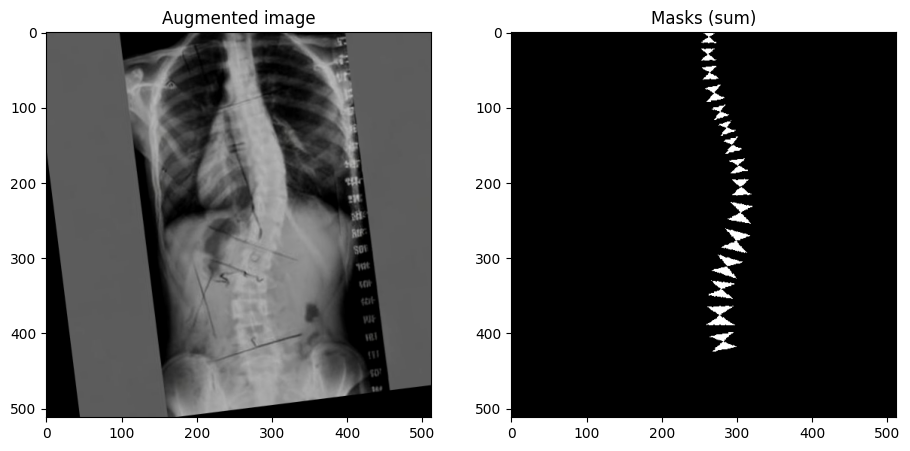

In [ ]:
images, targets = next(iter(train_loader))
print("Images/batch:", len(images), "| img0 shape:", images[0].shape)
print("Boxes0:", targets[0]["boxes"].shape, "| Masks0:", targets[0]["masks"].shape)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(images[0].permute(1, 2, 0).numpy()); ax[0].set_title("Augmented image")
ax[1].imshow(targets[0]["masks"].sum(0).numpy(), cmap="gray"); ax[1].set_title("Masks (sum)")
plt.show()

In [ ]:
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

NUM_CLASSES = 2
model = torchvision.models.detection.maskrcnn_resnet50_fpn(weights="DEFAULT")

in_feat = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_feat, NUM_CLASSES)

in_feat_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
model.roi_heads.mask_predictor = MaskRCNNPredictor(in_feat_mask, 256, NUM_CLASSES)

model.to(device)
print("Model ready and defined on:", device)

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:00<00:00, 206MB/s]


Model ready and defined on: cuda


In [ ]:
NUM_EPOCHS = 10
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(params, lr=1e-4, weight_decay=1e-4)

warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer, start_factor=0.1, end_factor=1.0, total_iters=1
)
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=NUM_EPOCHS - 1
)
lr_scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer, schedulers=[warmup_scheduler, cosine_scheduler], milestones=[1]
)
print(f"Optimizer AdamW + Warmup(1ep) + CosineAnnealingLR(T_max={NUM_EPOCHS-1})")

Optimizer AdamW + Warmup(1ep) + CosineAnnealingLR(T_max=9)


In [ ]:
def train_one_epoch(model, optimizer, loader, device, epoch, print_freq=200, max_grad_norm=5.0):
    model.train()
    running = 0.0
    n_seen = 0
    for i, (images, targets) in enumerate(loader):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        loss_dict = model(images, targets)
        losses = sum(loss_dict.values())
        optimizer.zero_grad()
        losses.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
        optimizer.step()
        running += losses.item()
        n_seen += 1
        if i % print_freq == 0:
            avg = running / n_seen
            print(f"  Epoch {epoch} | iter {i}/{len(loader)} | loss {losses.item():.4f} | avg {avg:.4f}")
    return running / max(n_seen, 1)

In [ ]:
@torch.no_grad()
def evaluate_loss(model, loader, device):
    model.train()
    total, n = 0.0, 0

    VALID_KEYS = {"boxes", "labels", "masks", "image_id", "area", "iscrowd"}
    for images, targets in loader:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items() if k in VALID_KEYS} for t in targets]
        loss_dict = model(images, targets)
        total += sum(loss_dict.values()).item()
        n += 1
    model.eval()
    return total / max(n, 1)

print("evaluate_loss defined (filtre is_dummy, @torch.no_grad).")

evaluate_loss defined (filtre is_dummy, @torch.no_grad).


In [ ]:
VALID_KEYS = {"boxes", "labels", "masks", "image_id", "area", "iscrowd"}

def train_one_epoch(model, optimizer, loader, device, epoch, print_freq=200, max_grad_norm=5.0):
    model.train()
    running, n_seen = 0.0, 0
    for i, (images, targets) in enumerate(loader):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items() if k in VALID_KEYS} for t in targets]
        loss_dict = model(images, targets)
        losses = sum(loss_dict.values())
        optimizer.zero_grad(); losses.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
        optimizer.step()
        running += losses.item(); n_seen += 1
        if i % print_freq == 0:
            print(f"  Epoch {epoch} | iter {i}/{len(loader)} | loss {losses.item():.4f} | avg {running/n_seen:.4f}")
    return running / max(n_seen, 1)


start_epoch = 1
best_val = float("inf"); best_wts = None
train_loss_history, val_loss_history = [], []

if LATEST_CKPT.exists():
    print(f"[RESUME] Checkpoint trouvé : {LATEST_CKPT}")
    ckpt = torch.load(LATEST_CKPT, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    lr_scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    start_epoch        = ckpt["epoch"] + 1
    best_val           = ckpt.get("best_val", float("inf"))
    best_wts           = ckpt.get("best_wts", None)
    train_loss_history = ckpt.get("train_loss_history", [])
    val_loss_history   = ckpt.get("val_loss_history", [])
    print(f"[RESUME] Reprise à l'époque {start_epoch}/{NUM_EPOCHS} | best_val={best_val:.4f}")
else:
    print("[INFO] Aucun checkpoint -> entraînement depuis le début.")


for epoch in range(start_epoch, NUM_EPOCHS + 1):
    print(f"\n=== Epoch {epoch}/{NUM_EPOCHS} | LR = {optimizer.param_groups[0]['lr']:.2e} ===")
    tr = train_one_epoch(model, optimizer, train_loader, device, epoch)
    vl = evaluate_loss(model, val_loader, device)
    lr_scheduler.step()
    train_loss_history.append(tr); val_loss_history.append(vl)
    print(f"Epoch {epoch}/{NUM_EPOCHS} | train {tr:.4f} | val {vl:.4f}")

    if vl < best_val:
        best_val = vl
        best_wts = copy.deepcopy(model.state_dict())
        torch.save({"epoch": epoch, "model_state_dict": best_wts, "val_loss": vl}, BEST_CKPT)
        torch.save({"epoch": epoch, "model_state_dict": best_wts, "val_loss": vl}, "/content/maskrcnn_spine_best.pth")
        print(f"  ✔ Best model saved (val={best_val:.4f})")


    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": lr_scheduler.state_dict(),
        "best_val": best_val,
        "best_wts": best_wts,
        "train_loss_history": train_loss_history,
        "val_loss_history": val_loss_history,
    }, LATEST_CKPT)
    print(f"   checkpoint_latest.pth mis à jour (epoch {epoch})")

if best_wts is not None:
    model.load_state_dict(best_wts)
print("\nTraining done. Best model reloaded.")

[RESUME] Checkpoint trouvé : /content/drive/MyDrive/spinal_AI_v6/checkpoints/checkpoint_latest.pth
[RESUME] Reprise à l'époque 11/10 | best_val=0.3501

Training done. Best model reloaded.


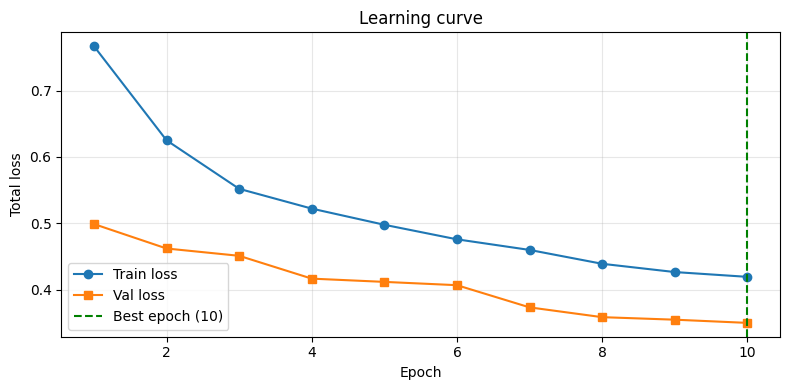

Best epoch: 10 | min val loss: 0.3501


In [ ]:
ep = range(1, len(train_loss_history) + 1)
best_ep = int(np.argmin(val_loss_history)) + 1

plt.figure(figsize=(8, 4))
plt.plot(ep, train_loss_history, "o-", label="Train loss")
plt.plot(ep, val_loss_history,   "s-", label="Val loss")
plt.axvline(best_ep, color="green", ls="--", label=f"Best epoch ({best_ep})")
plt.xlabel("Epoch"); plt.ylabel("Total loss"); plt.title("Learning curve")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print("Best epoch:", best_ep, "| min val loss:", round(min(val_loss_history), 4))

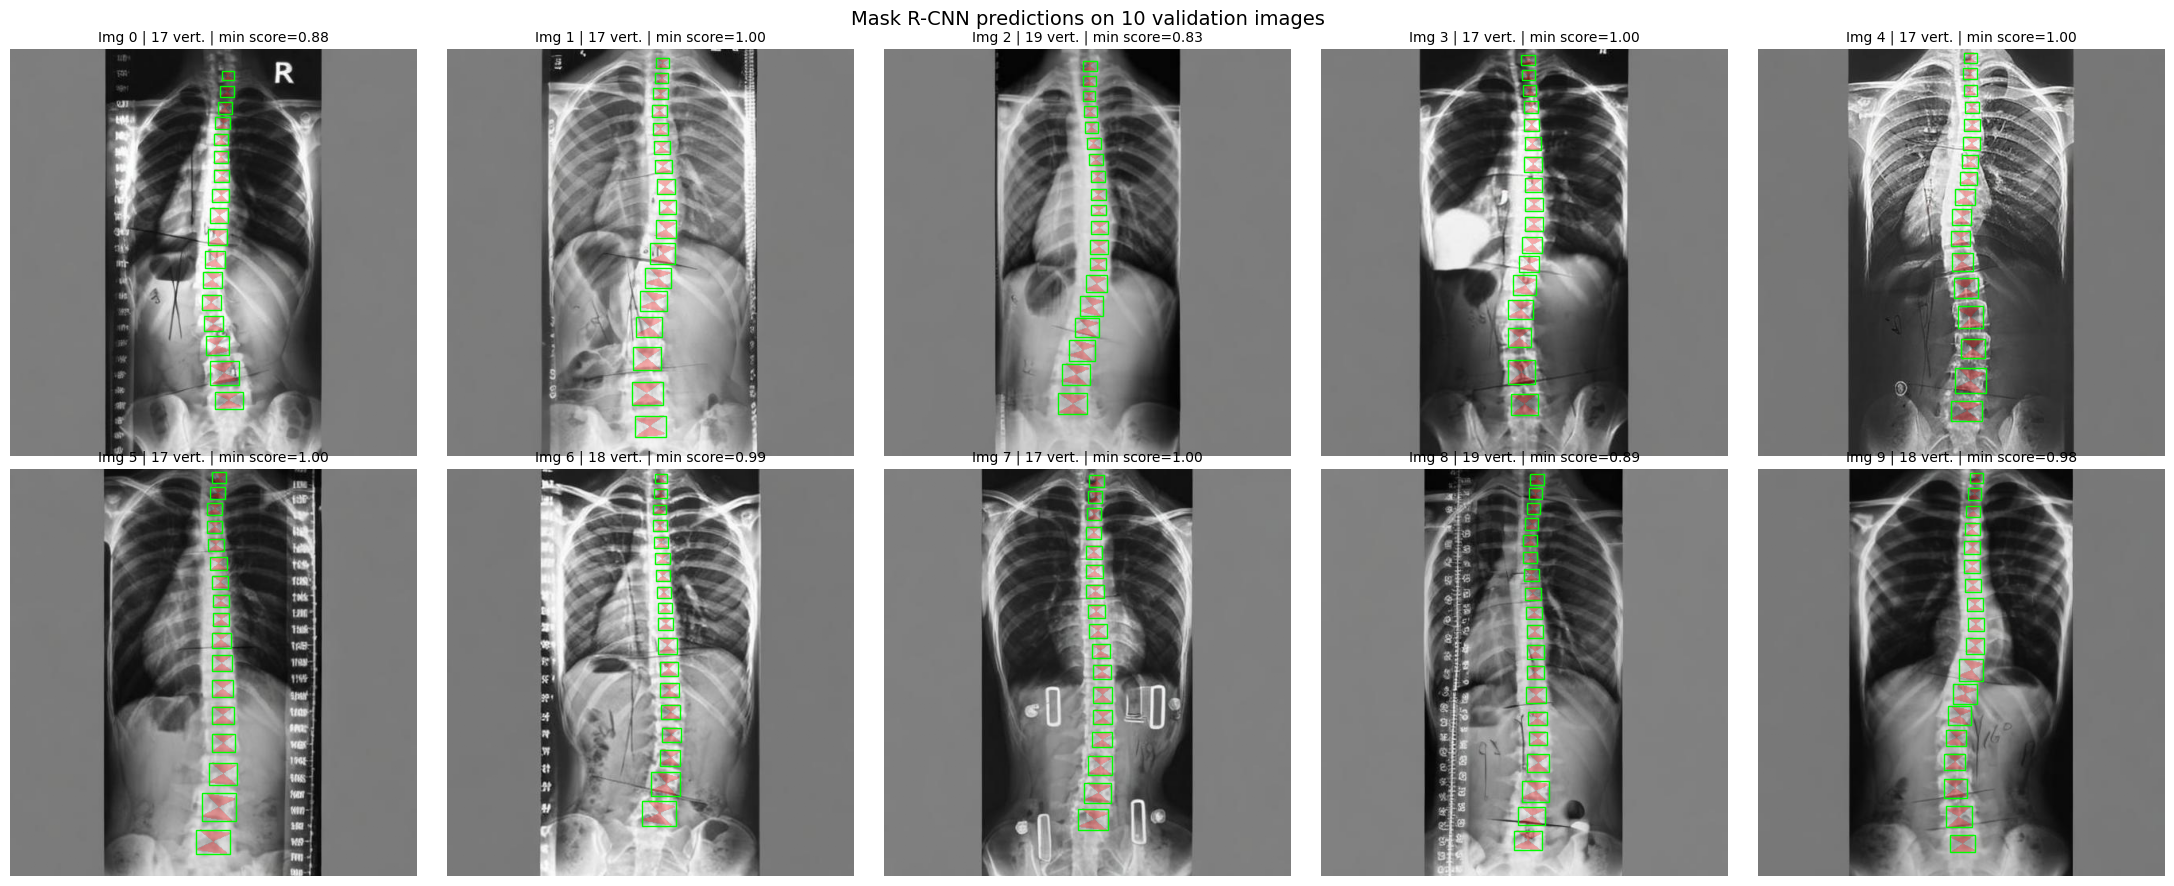

In [ ]:
model.eval()

N_VIS = 10
indices = list(range(N_VIS))

fig, axes = plt.subplots(2, 5, figsize=(22, 9))
axes = axes.flatten()

for ax_idx, vidx in enumerate(indices):
    val_img, _ = val_dataset[vidx]

    with torch.no_grad():
        pred = model([val_img.to(device)])[0]

    keep = pred["scores"].cpu().numpy() >= 0.5
    boxes = pred["boxes"].cpu().numpy()[keep]
    masks = pred["masks"].cpu().numpy()[keep]
    scores = pred["scores"].cpu().numpy()[keep]

    img_np = val_img.permute(1, 2, 0).cpu().numpy()
    ax = axes[ax_idx]
    ax.imshow(img_np)

    for i in range(len(boxes)):
        x1, y1, x2, y2 = boxes[i]
        ax.add_patch(
            plt.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor="lime",
                lw=1
            )
        )
        m = masks[i, 0] > 0.5
        ax.imshow(np.ma.masked_where(~m, m), alpha=0.3, cmap="autumn")

    mn = scores.min() if len(scores) else float("nan")
    ax.set_title(f"Img {vidx} | {len(boxes)} vert. | min score={mn:.2f}", fontsize=10)
    ax.axis("off")

plt.suptitle("Mask R-CNN predictions on 10 validation images", fontsize=14)
plt.tight_layout()


plt.show()

In [ ]:
import re
TRAIN_COBB_GT = DATASET_ROOT / "Cobb_spinal-AI2024-train_gt.txt"
TEST_COBB_GT  = DATASET_ROOT / "Cobb_spinal-AI2024-test_gt.txt"

def load_cobb_gt(filepath, images_by_id=None, verbose=True):
    gt = {}
    if not os.path.exists(filepath):
        print(f"[WARNING] File not found: {filepath}")
        return gt

    filename_to_id = {}
    if images_by_id is not None:
        for img_id, info in images_by_id.items():
            fname = Path(info["file_name"]).name
            filename_to_id[fname] = img_id

    with open(filepath, "r", encoding="utf-8", errors="ignore") as f:
        lines = [l.strip() for l in f if l.strip() and not l.strip().startswith("#")]

    if verbose:
        print(f"=== {os.path.basename(filepath)} — first 5 lines ===")
        for l in lines[:5]:
            print("  ", repr(l))

    matched, unmatched = 0, 0
    for line in lines:
        parts = line.split(",")
        if len(parts) < 4:
            continue
        fname = parts[0].strip()
        try:
            angles = [float(x) for x in parts[1:4]]
        except ValueError:
            continue
        img_id = filename_to_id.get(fname)
        if img_id is None:
            unmatched += 1
            continue
        gt[img_id] = {
            "PT": angles[0], "MT": angles[1], "TL_L": angles[2],
            "max_cobb": max(abs(a) for a in angles),
        }
        matched += 1

    print(f"-> {matched} GT entries matched by filename | {unmatched} unmatched")
    return gt

train_cobb_gt = load_cobb_gt(TRAIN_COBB_GT, images_by_id=images_by_id)
test_cobb_gt  = load_cobb_gt(TEST_COBB_GT,  images_by_id=test_images_by_id)

=== Cobb_spinal-AI2024-train_gt.txt — first 5 lines ===
   '000001.jpg,2.87,11.01,8.87'
   '000002.jpg,3.18,9.35,16.48'
   '000003.jpg,7.14,16.33,11.51'
   '000004.jpg,4.53,19.2,26.7'
   '000005.jpg,5.04,6.71,5.87'
-> 15999 GT entries matched by filename | 0 unmatched
=== Cobb_spinal-AI2024-test_gt.txt — first 5 lines ===
   '016001.jpg,0.0,4.09,12.45'
   '016002.jpg,7.77,21.09,24.34'
   '016003.jpg,5.8,11.17,15.37'
   '016004.jpg,0.0,11.94,20.01'
   '016005.jpg,9.97,16.88,20.77'
-> 4000 GT entries matched by filename | 0 unmatched


In [ ]:
def get_vertebra_endplates(binary_mask):


    ys, xs = np.where(binary_mask > 0)

    if len(xs) < 10:
        return None

    contours, _ = cv2.findContours(
        binary_mask.astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )
    if not contours:
        return None

    cnt = max(contours, key=cv2.contourArea)
    if len(cnt) < 5:
        return None

    rect = cv2.minAreaRect(cnt)
    (rect_cx, rect_cy), (w, h), angle = rect

    # S'assurer que w >= h
    if w < h:
        w, h = h, w
        angle = angle + 90

    rect_corrected = ((rect_cx, rect_cy), (w, h), angle)
    box = cv2.boxPoints(rect_corrected)
    box = np.array(box, dtype=np.float32)

    order = np.argsort(box[:, 1])
    top_pts = box[order[:2]]
    bot_pts = box[order[2:]]
    top_pts = top_pts[np.argsort(top_pts[:, 0])]
    bot_pts = bot_pts[np.argsort(bot_pts[:, 0])]

    (xtl, ytl), (xtr, ytr) = top_pts[0], top_pts[1]
    (xbl, ybl), (xbr, ybr) = bot_pts[0], bot_pts[1]

    def slope(x1, y1, x2, y2):
        dx = x2 - x1
        if abs(dx) < 1e-6:
            return float("inf")
        return (y2 - y1) / dx

    upper_slope = slope(xtl, ytl, xtr, ytr)
    lower_slope = slope(xbl, ybl, xbr, ybr)
    cx, cy = float(xs.mean()), float(ys.mean())

    return {
        "upper_slope": upper_slope,
        "lower_slope": lower_slope,
        "upper_line": ((float(xtl), float(ytl)), (float(xtr), float(ytr))),
        "lower_line": ((float(xbl), float(ybl)), (float(xbr), float(ybr))),
        "corners": {
            "top_left":     (float(xtl), float(ytl)),
            "top_right":    (float(xtr), float(ytr)),
            "bottom_left":  (float(xbl), float(ybl)),
            "bottom_right": (float(xbr), float(ybr)),
        },
        "cx": cx,
        "cy": cy,
        "area": int(binary_mask.sum())
    }

print("get_vertebra_endplates défini correctement.")

get_vertebra_endplates défini correctement.


In [ ]:
def extract_vertebra_geometry(masks_pred, scores, score_thr=0.5, mask_thr=0.5,
                              nms_dist=15, image_height=None):
    # minimum 15px pour éviter la fusion de vertèbres adjacentes
    if image_height is not None:
        nms_dist = max(int(0.025 * image_height), 15)

    candidates = []
    for i in range(len(masks_pred)):
        if scores[i] < score_thr:
            continue
        m = (masks_pred[i, 0] > mask_thr).astype(np.uint8)
        g = get_vertebra_endplates(m)
        if g is None:
            continue
        g["score"] = float(scores[i])
        candidates.append(g)

    candidates.sort(key=lambda v: v["cy"])
    kept = []
    for c in candidates:
        if not kept or abs(c["cy"] - kept[-1]["cy"]) > nms_dist:
            kept.append(c)
        elif c["score"] > kept[-1]["score"]:
            kept[-1] = c
    return kept

print("extract_vertebra_geometry defined (nms_dist min=15px).")

extract_vertebra_geometry defined (nms_dist min=15px).


In [ ]:
import numpy as np

def compute_cobb_angle(verts):
    n = len(verts)
    if n < 3:
        return None, None, None

    best_angle = -1.0
    best_i, best_j = None, None

    for i in range(n - 1):
        m_u = verts[i]["upper_slope"]
        if np.isinf(m_u):
            continue

        for j in range(i + 1, n):
            # Contrainte clinique : au moins 3 vertèbres dans la courbe
            if (j - i) < 2:
                continue

            m_l = verts[j]["lower_slope"]
            if np.isinf(m_l):
                continue

            denom = 1.0 + m_u * m_l
            if abs(denom) < 1e-6:
                angle = 90.0
            else:
                angle = abs(np.degrees(np.arctan(abs(m_u - m_l) / abs(denom))))

            if angle > best_angle:
                best_angle = angle
                best_i, best_j = i, j

    if best_angle < 0:
        return None, None, None

    return best_angle, best_i, best_j


def classify_scoliosis(angle):
    if angle is None:
        return "Unknown"
    elif 10 <= angle < 25:
        return "Mild"
    elif 25 <= angle <= 40:
        return "Moderate"
    elif angle > 40:
        return "Severe"


print("compute_cobb_angle + classify_scoliosis defined.")

compute_cobb_angle + classify_scoliosis defined.


In [ ]:
model.eval()
val_img, _ = val_dataset[0]
H_img = val_img.shape[1]
with torch.no_grad():
    p = model([val_img.to(device)])[0]
sc = p["scores"].cpu().numpy(); mk = p["masks"].cpu().numpy()
verts = extract_vertebra_geometry(mk, sc, image_height=H_img)
print(f"Vertebrae detected: {len(verts)}")
for i, v in enumerate(verts):
    u = v['upper_slope']; l = v['lower_slope']
    print(f"  V{i+1:02d} | cy={v['cy']:6.1f} | upper={u:+.4f} | lower={l:+.4f}")
cobb, ui, li = compute_cobb_angle(verts)
if cobb is not None:
    print(f"\nCobb angle: {cobb:.2f}° -> {classify_scoliosis(cobb)}")
else:
    print("\nCobb not computed (need >= 3 vertebrae).")

Vertebrae detected: 17
  V01 | cy=  33.5 | upper=+0.0000 | lower=+0.0000
  V02 | cy=  53.3 | upper=+0.0000 | lower=+0.0000
  V03 | cy=  73.7 | upper=+0.1429 | lower=+0.1429
  V04 | cy=  93.7 | upper=+0.1667 | lower=+0.1667
  V05 | cy= 113.4 | upper=+0.0000 | lower=+0.0000
  V06 | cy= 134.9 | upper=+0.0000 | lower=+0.0000
  V07 | cy= 158.5 | upper=+0.0000 | lower=+0.0000
  V08 | cy= 183.8 | upper=+0.0000 | lower=+0.0000
  V09 | cy= 209.4 | upper=+0.1176 | lower=+0.1176
  V10 | cy= 236.7 | upper=+0.1111 | lower=+0.1111
  V11 | cy= 264.2 | upper=+0.1667 | lower=+0.1667
  V12 | cy= 290.2 | upper=+0.1429 | lower=+0.1429
  V13 | cy= 318.2 | upper=+0.0000 | lower=+0.0000
  V14 | cy= 345.6 | upper=+0.0000 | lower=+0.0000
  V15 | cy= 372.9 | upper=-0.2000 | lower=-0.2000
  V16 | cy= 407.2 | upper=-0.1905 | lower=-0.1905
  V17 | cy= 441.6 | upper=-0.0909 | lower=-0.0909

Cobb angle: 20.77° -> Mild


In [ ]:
from pathlib import Path

FIGDIR = Path("./figures")
FIGDIR.mkdir(exist_ok=True)
print(f"FIGDIR est maintenant défini sur : {FIGDIR}")

FIGDIR est maintenant défini sur : figures


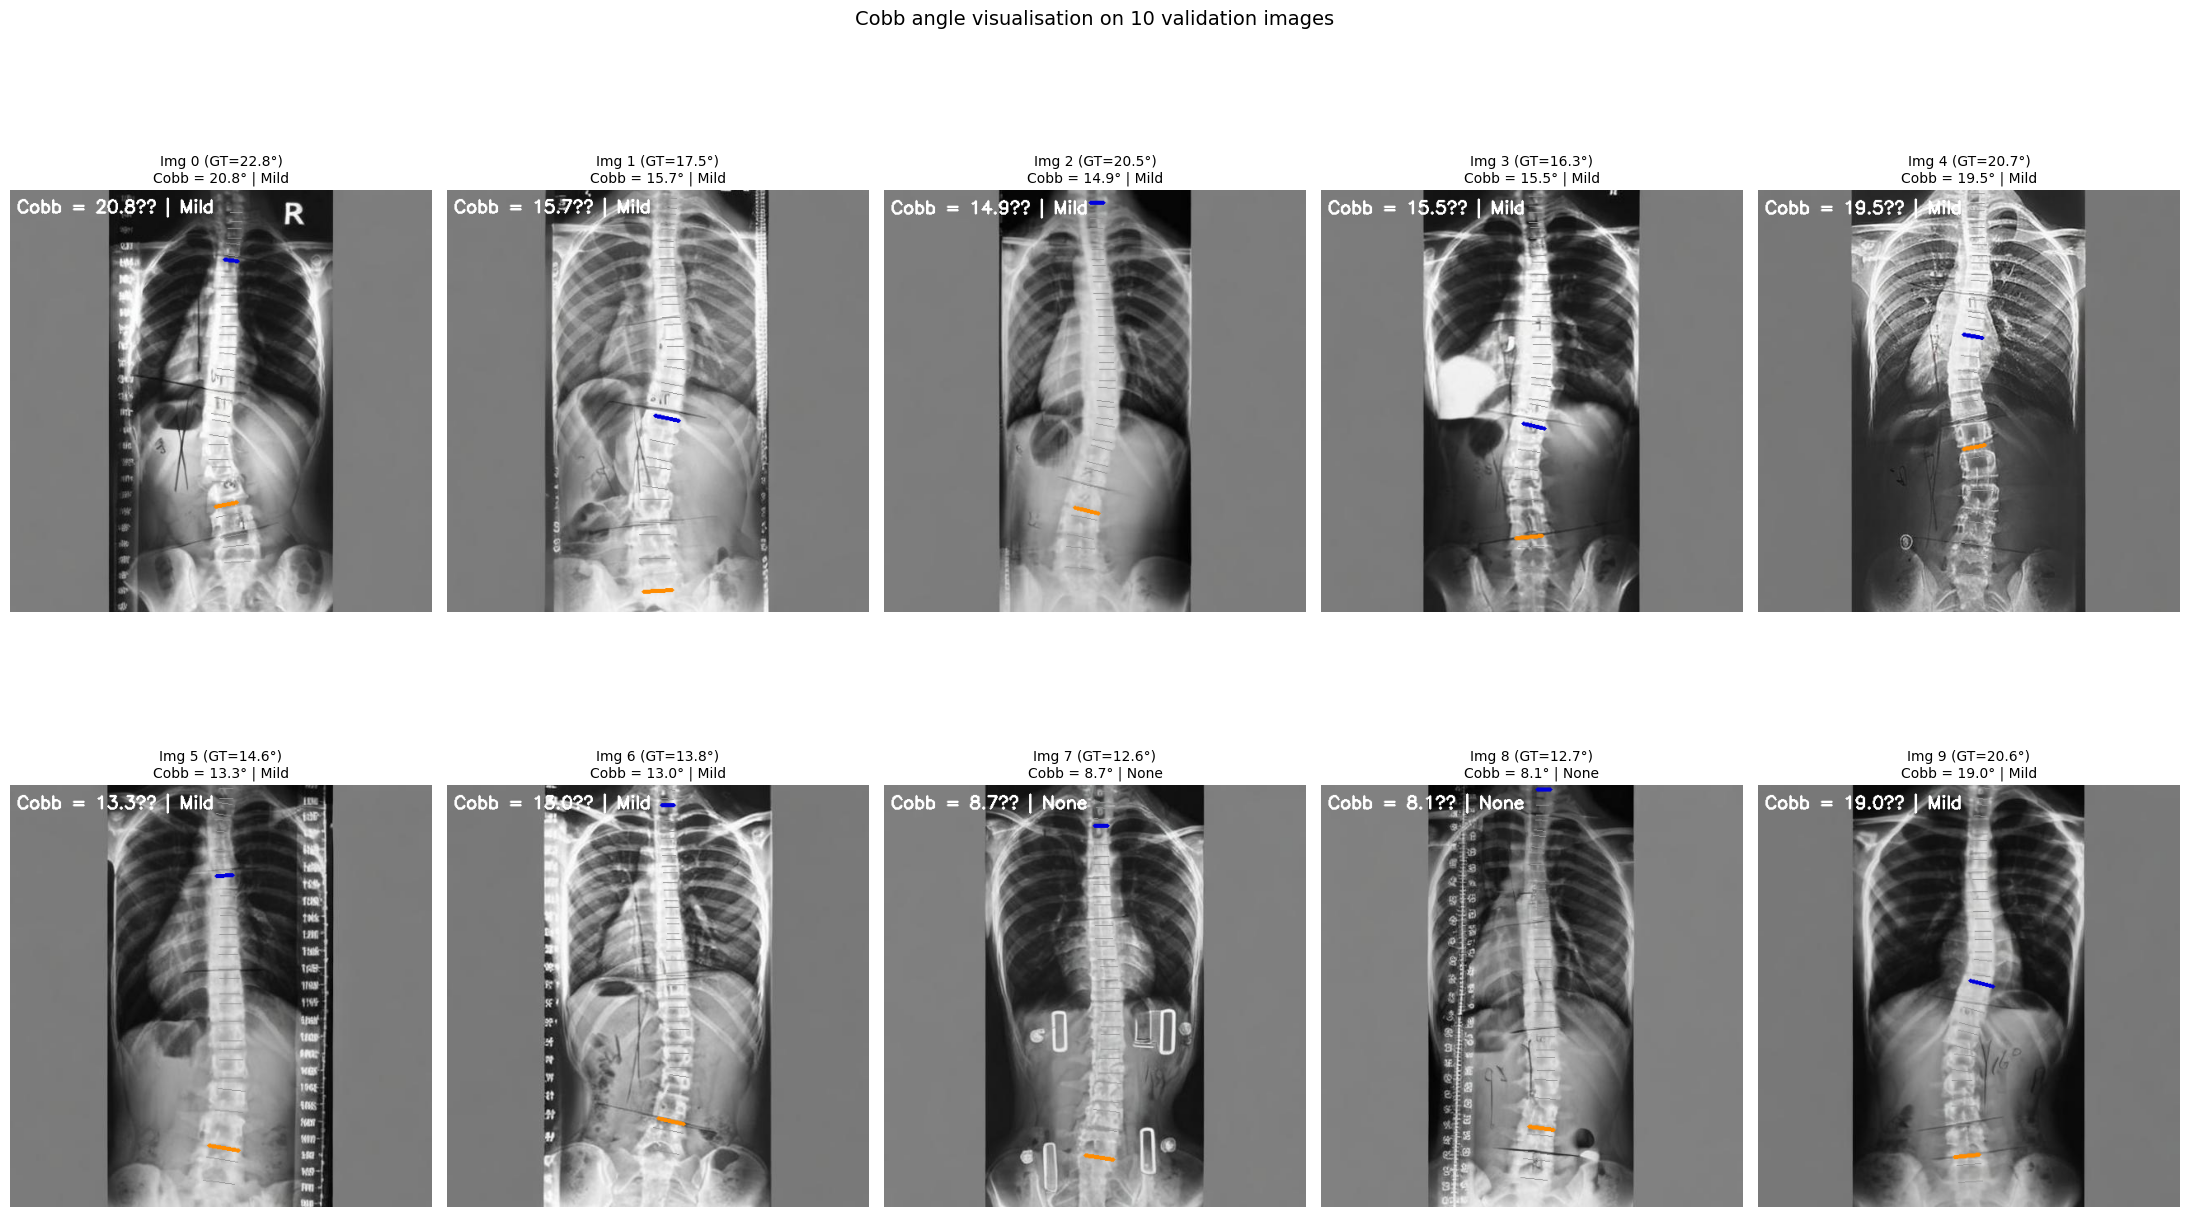

In [ ]:
def visualize_cobb_on_ax(ax, img_np, verts, u_idx, l_idx, cobb, severity, title_prefix=""):
    vis = (np.clip(img_np, 0, 1) * 255).astype(np.uint8)
    vis = cv2.cvtColor(vis, cv2.COLOR_RGB2BGR)

    def draw_line(line, color, w):
        if line is None:
            return
        (x1, y1), (x2, y2) = line
        cv2.line(vis, (int(x1), int(y1)), (int(x2), int(y2)), color, w)

    for i, v in enumerate(verts):
        if i == u_idx:
            draw_line(v["upper_line"], (220, 0, 0), 3)
        elif i == l_idx:
            draw_line(v["lower_line"], (0, 140, 255), 3)
        else:
            draw_line(v["upper_line"], (150, 150, 150), 1)
            draw_line(v["lower_line"], (150, 150, 150), 1)

    label = f"Cobb = {cobb:.1f}° | {severity}" if cobb is not None else "Not computed"
    cv2.putText(vis, label, (8, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)

    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{title_prefix}{label}", fontsize=10)
    ax.axis("off")


model.eval()

N_VIS = 10
indices = list(range(N_VIS))

fig, axes = plt.subplots(2, 5, figsize=(22, 14))
axes = axes.flatten()

for ax_idx, vidx in enumerate(indices):
    vimg, vtgt = val_dataset[vidx]
    H_img = vimg.shape[1]

    with torch.no_grad():
        pr = model([vimg.to(device)])[0]

    verts_i = extract_vertebra_geometry(
        pr["masks"].cpu().numpy(),
        pr["scores"].cpu().numpy(),
        image_height=H_img
    )

    cobb_i, u_i, l_i = compute_cobb_angle(verts_i)
    sev_i = classify_scoliosis(cobb_i)

    img_id = int(vtgt["image_id"].item())
    gt = train_cobb_gt.get(img_id, {}).get("max_cobb", None)
    gt_str = f" (GT={gt:.1f}°)" if gt is not None else ""

    img_np = vimg.permute(1, 2, 0).cpu().numpy()

    if cobb_i is not None:
        visualize_cobb_on_ax(
            axes[ax_idx],
            img_np,
            verts_i,
            u_i,
            l_i,
            cobb_i,
            sev_i,
            title_prefix=f"Img {vidx}{gt_str}\n"
        )
    else:
        axes[ax_idx].imshow(img_np)
        axes[ax_idx].set_title(f"Img {vidx}{gt_str}\nCobb not computed", fontsize=10)
        axes[ax_idx].axis("off")

plt.suptitle("Cobb angle visualisation on 10 validation images", fontsize=14)
plt.tight_layout()

plt.savefig(FIGDIR / "fig_cobb_visualisation_val.png", dpi=300, bbox_inches="tight")
plt.savefig(FIGDIR / "fig_cobb_visualisation_val.pdf", bbox_inches="tight")

plt.show()

In [ ]:
from tqdm import tqdm
model.eval()
NUM_EVAL = len(val_dataset)
results = []
for idx in tqdm(range(NUM_EVAL), desc="Eval Cobb (val)"):
    vimg, vtgt = val_dataset[idx]
    H_img = vimg.shape[1]
    with torch.no_grad():
        pr = model([vimg.to(device)])[0]
    verts_i = extract_vertebra_geometry(pr["masks"].cpu().numpy(),
                                        pr["scores"].cpu().numpy(),
                                        image_height=H_img)
    cobb_i, u_i, l_i = compute_cobb_angle(verts_i)
    img_id = int(vtgt["image_id"].item())
    gt = train_cobb_gt.get(img_id, {}).get("max_cobb", None)
    results.append({"image_id": img_id, "n_verts": len(verts_i),
                    "cobb": round(cobb_i, 2) if cobb_i else None,
                    "gt_cobb": round(gt, 2) if gt is not None else None,
                    "severity": classify_scoliosis(cobb_i)})

df_results = pd.DataFrame(results)
common = df_results.dropna(subset=["cobb", "gt_cobb"])
print(f"\nVal evaluated on {len(df_results)} images | usable pairs: {len(common)}")
if len(common):
    mae_val  = (common['cobb'] - common['gt_cobb']).abs().mean()
    rmse_val = np.sqrt(((common['cobb'] - common['gt_cobb'])**2).mean())
    print(f"MAE  (val): {mae_val:.2f}°")
    print(f"RMSE (val): {rmse_val:.2f}°")
print(df_results.head(20).to_string(index=False))

Eval Cobb (val): 100%|██████████| 1600/1600 [04:32<00:00,  5.87it/s]


Val evaluated on 1600 images | usable pairs: 1597
MAE  (val): 2.56°
RMSE (val): 5.22°
 image_id  n_verts      cobb  gt_cobb severity
    11534       17 20.770000    22.76     Mild
    10385       17 15.710000    17.54     Mild
    12459       19 14.930000    20.46     Mild
    15647       17 15.550000    16.33     Mild
     7111       17 19.469999    20.74     Mild
     1481       17 13.280000    14.57     Mild
    12237       18 12.990000    13.79     Mild
    14801       17  8.750000    12.55     None
     4709       19  8.130000    12.66     None
    11215       18 19.010000    20.57     Mild
    10342       17 14.230000    16.99     Mild
     3847       16 20.379999    18.75     Mild
     1122       18  6.340000    10.91     None
    10118       18 25.520000    27.79 Moderate
      589       17 27.700001    26.61 Moderate
     8866       16 23.650000    23.91     Mild
    15724       18 14.470000    14.91     Mild
     7995       17 20.280001    18.33     Mild
    12444       18  

In [ ]:
def iou_single(a, b):
    inter = np.logical_and(a, b).sum(); union = np.logical_or(a, b).sum()
    return inter / union if union > 0 else 0.0

def dice_single(a, b):
    inter = np.logical_and(a, b).sum(); denom = a.sum() + b.sum()
    return (2 * inter) / denom if denom > 0 else 0.0

def evaluate_segmentation(model, dataset, device, n_samples=None, thr=0.5):
    model.eval()
    n = len(dataset) if n_samples is None else min(n_samples, len(dataset))
    per_image = []
    for idx in tqdm(range(n), desc="Eval segmentation"):
        img_t, tgt = dataset[idx]
        with torch.no_grad():
            pr = model([img_t.to(device)])[0]
        sc = pr["scores"].cpu().numpy()
        mp = pr["masks"].cpu().numpy()
        pred = [(mp[i, 0] > thr) for i in range(len(mp)) if sc[i] >= 0.5]
        gt = [m.astype(bool) for m in tgt["masks"].numpy()]
        if not pred or not gt:
            per_image.append({"idx": idx, "iou": 0.0, "dice": 0.0,
                              "n_pred": len(pred), "n_gt": len(gt)})
            continue
        used, ious, dices = set(), [], []
        for pm in pred:
            best, bj = -1, -1
            for j, gm in enumerate(gt):
                if j in used: continue
                v = iou_single(pm, gm)
                if v > best: best, bj = v, j
            if bj >= 0:
                used.add(bj); ious.append(best); dices.append(dice_single(pm, gt[bj]))
        per_image.append({"idx": idx,
                          "iou": float(np.mean(ious)) if ious else 0.0,
                          "dice": float(np.mean(dices)) if dices else 0.0,
                          "n_pred": len(pred), "n_gt": len(gt)})
    miou  = float(np.mean([r["iou"] for r in per_image]))
    mdice = float(np.mean([r["dice"] for r in per_image]))
    return miou, mdice, per_image

print("evaluate_segmentation defined.")

evaluate_segmentation defined.


In [ ]:
N_EVAL = min(500, len(val_dataset))
mean_iou, mean_dice, per_image = evaluate_segmentation(model, val_dataset, device, n_samples=N_EVAL)
df_metrics = pd.DataFrame(per_image)

iou_arr  = df_metrics["iou"].values
dice_arr = df_metrics["dice"].values

print(f"\nMean IoU  : {mean_iou:.4f} ± {df_metrics['iou'].std():.4f}")
print(f"Mean Dice : {mean_dice:.4f} ± {df_metrics['dice'].std():.4f}")
print(f"Evaluated on {len(df_metrics)} val images")
print(df_metrics.head(15).to_string(index=False))

Eval segmentation: 100%|██████████| 500/500 [02:30<00:00,  3.33it/s]


Mean IoU  : 0.7845 ± 0.0490
Mean Dice : 0.8740 ± 0.0396
Evaluated on 500 val images
 idx      iou     dice  n_pred  n_gt
   0 0.773681 0.869920      17    17
   1 0.823886 0.901655      17    17
   2 0.808065 0.892010      19    18
   3 0.837015 0.909965      17    17
   4 0.817879 0.898733      17    17
   5 0.799733 0.886552      17    17
   6 0.800090 0.887817      18    18
   7 0.796355 0.884623      17    17
   8 0.817763 0.898316      19    18
   9 0.791693 0.882353      18    18
  10 0.820669 0.899846      17    17
  11 0.805877 0.890895      16    16
  12 0.807030 0.891317      18    18
  13 0.825201 0.903517      18    18
  14 0.806638 0.890347      17    17


In [ ]:
from pathlib import Path
FIGDIR = Path("/content/thesis_figures")
FIGDIR.mkdir(exist_ok=True)
FIG_DIR = FIGDIR  # alias

def save_fig(name, dpi=300):
    plt.savefig(FIGDIR / f"{name}.png", dpi=dpi, bbox_inches="tight")
    plt.savefig(FIGDIR / f"{name}.pdf", bbox_inches="tight")
    print(f"  ✓ Saved {name}.png / .pdf")

plt.rcParams.update({
    "figure.dpi": 150, "font.family": "DejaVu Sans",
    "font.size": 11, "axes.titlesize": 13, "axes.labelsize": 11,
    "legend.fontsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
})
print("Export config ready ->", FIGDIR)

Export config ready -> /content/thesis_figures


In [ ]:
from pycocotools.cocoeval import COCOeval
from pycocotools.coco import COCO

def compute_coco_segm_ap(model, dataset, coco_gt, img_ids, device, score_thr=0.05):
    model.eval()
    detections = []
    for i in range(len(dataset)):
        img_t, tgt = dataset[i]
        image_id = int(tgt["image_id"].item())
        with torch.no_grad():
            pr = model([img_t.to(device)])[0]
        masks  = pr["masks"].cpu().numpy()
        scores = pr["scores"].cpu().numpy()
        labels = pr["labels"].cpu().numpy()
        boxes  = pr["boxes"].cpu().numpy()
        for k in range(len(scores)):
            if scores[k] < score_thr:
                continue
            m = np.asfortranarray((masks[k, 0] > 0.5).astype(np.uint8))
            rle = maskUtils.encode(m)
            rle["counts"] = rle["counts"].decode("ascii")
            x1, y1, x2, y2 = boxes[k]
            detections.append({
                "image_id": image_id,
                "category_id": int(labels[k]),
                "segmentation": rle,
                "score": float(scores[k]),
                "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)],
            })
    if not detections:
        return float("nan"), float("nan")
    coco_dt = coco_gt.loadRes(detections)
    ev = COCOeval(coco_gt, coco_dt, iouType="segm")
    ev.params.imgIds = list(img_ids)
    ev.evaluate(); ev.accumulate(); ev.summarize()
    return float(ev.stats[1]), float(ev.stats[0])  # AP@0.50 , AP@[0.50:0.95]

coco_gt = COCO(str(TRAIN_JSON))
ap_50, ap_50_95 = compute_coco_segm_ap(model, val_dataset, coco_gt, val_ids, device)
print(f"AP@0.50 = {ap_50:.4f} | AP@[0.50:0.95] = {ap_50_95:.4f}")

loading annotations into memory...
Done (t=1.60s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.04s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=9.23s).
Accumulating evaluation results...
DONE (t=0.36s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.576
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.976
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.648
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.566
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.631
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = -1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.043
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.393
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

Eval Cobb (test): 100%|██████████| 4000/4000 [11:12<00:00,  5.95it/s]


SEVERITY DISTRIBUTION - ALL TEST SET (4000 images)

Severity distribution — PREDICTED (test):
severity
Mild        2373
Moderate     617
Severe       422

Severity distribution — GROUND TRUTH (test):
severity_gt
Mild        2616
Moderate     675
Severe       431

MAE (test): 2.87° on 4000 images
RMSE (test): 6.06°

SEVERITY DISTRIBUTION - EVALUATION SUBSET (3387 images)
(Excludes 'Normal' class and samples with missing predictions)

Severity distribution — PREDICTED (common subset):
severity
Mild        2352
Moderate     614
Severe       421

Severity distribution — GROUND TRUTH (common subset):
severity_gt
Mild        2281
Moderate     675
Severe       431

Severity classification accuracy: 94.66%

Confusion matrix (rows=GT, cols=Pred):
          Mild  Moderate  Severe
Mild      2239        42       0
Moderate   113       554       8
Severe       0        18     413

Per-class report:
              precision    recall  f1-score   support

        Mild       0.95      0.98      0.97   

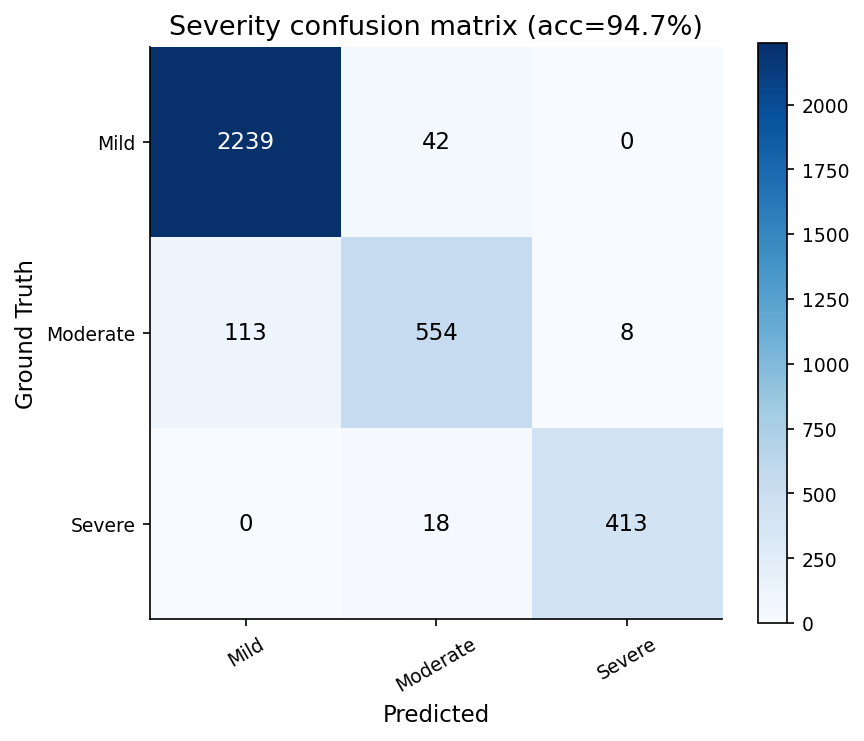


SUMMARY
Total test images: 4000
Images with valid Cobb angles: 4000
Images in 3-class evaluation: 3387
Excluded (Normal or missing): 613

 All the variables needed for the following cells are set.


In [ ]:
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    r2_score, f1_score, cohen_kappa_score
)
from scipy.stats import pearsonr

model.eval()
N_TEST = len(test_dataset)
test_results = []

for idx in tqdm(range(N_TEST), desc="Eval Cobb (test)"):
    img_t, tgt_t = test_dataset[idx]
    H_img = img_t.shape[1]

    with torch.no_grad():
        pr = model([img_t.to(device)])[0]
        verts_t = extract_vertebra_geometry(
            pr["masks"].cpu().numpy(),
            pr["scores"].cpu().numpy(),
            image_height=H_img
        )
        cobb_t, _, _ = compute_cobb_angle(verts_t)

        img_id = int(tgt_t["image_id"].item())
        gt = test_cobb_gt.get(img_id, {}).get("max_cobb", None)

        test_results.append({
            "image_id": img_id,
            "n_verts": len(verts_t),
            "cobb": round(cobb_t, 2) if cobb_t is not None else None,
            "gt_cobb": round(gt, 2) if gt is not None else None,
            "severity": classify_scoliosis(cobb_t),
            "severity_gt": classify_scoliosis(gt) if gt is not None else None
        })

df_test = pd.DataFrame(test_results)

# ============================================
# ✅ CORRECTION ICI : Afficher TOUTES les classes (y compris Normal)
# ============================================
print("="*60)
print("SEVERITY DISTRIBUTION - ALL TEST SET (4000 images)")
print("="*60)
print("\nSeverity distribution — PREDICTED (test):")
print(df_test["severity"].value_counts().to_string())

print("\nSeverity distribution — GROUND TRUTH (test):")
print(df_test["severity_gt"].value_counts().to_string())

# ============================================
# 1) Régression Cobb
# ============================================
common_t = df_test.dropna(subset=["cobb", "gt_cobb"])
mae_test = rmse_test = float("nan")
pred_arr = np.array([]); gt_arr = np.array([])
r2_test = r_pearson = within_5 = float("nan")

if len(common_t):
    pred_arr = common_t["cobb"].values.astype(float)
    gt_arr = common_t["gt_cobb"].values.astype(float)
    mae_test = np.abs(pred_arr - gt_arr).mean()
    rmse_test = np.sqrt(((pred_arr - gt_arr) ** 2).mean())
    within_5 = (np.abs(pred_arr - gt_arr) <= 5).mean() * 100

    print(f"\nMAE (test): {mae_test:.2f}° on {len(common_t)} images")
    print(f"RMSE (test): {rmse_test:.2f}°")

    if len(common_t) > 1:
        r2_test = r2_score(gt_arr, pred_arr)
        r_pearson, _ = pearsonr(gt_arr, pred_arr)

# ============================================
# 2) Classification sévérité (3 CLASSES uniquement)
# ============================================
labels = ["Mild", "Moderate", "Severe"]  # <-- FUSION Normal + Mild en Mild

#  CORRECTION : Utiliser common_sev pour TOUT (distributions + matrice)
common_sev = df_test.dropna(subset=["severity", "severity_gt"])

# Filtrer pour ne garder que les 3 classes (exclure Normal)
common_sev = common_sev[
    (common_sev["severity"].isin(labels)) &
    (common_sev["severity_gt"].isin(labels))
]

y_true = common_sev["severity_gt"].tolist()
y_pred = common_sev["severity"].tolist()

#  Afficher les distributions SUR LE MÊME SOUS-ENSEMBLE que la matrice
print("\n" + "="*60)
print(f"SEVERITY DISTRIBUTION - EVALUATION SUBSET ({len(common_sev)} images)")
print("(Excludes 'Normal' class and samples with missing predictions)")
print("="*60)
print("\nSeverity distribution — PREDICTED (common subset):")
print(common_sev["severity"].value_counts().to_string())

print("\nSeverity distribution — GROUND TRUTH (common subset):")
print(common_sev["severity_gt"].value_counts().to_string())

# Matrice de confusion
cm = confusion_matrix(y_true, y_pred, labels=labels)
acc = accuracy_score(y_true, y_pred) if len(y_true) else float("nan")
macro_f1 = f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)
kappa = cohen_kappa_score(y_true, y_pred, labels=labels) if len(y_true) else float("nan")

print(f"\nSeverity classification accuracy: {acc*100:.2f}%")
print("\nConfusion matrix (rows=GT, cols=Pred):")
df_cm = pd.DataFrame(cm, index=labels, columns=labels)
print(df_cm.to_string())

print("\nPer-class report:")
print(classification_report(y_true, y_pred, labels=labels, zero_division=0))

print(
    f"\nR2={r2_test:.4f} | Pearson r={r_pearson:.4f} | "
    f"within ±5°={within_5:.1f}% | macroF1={macro_f1:.4f} | kappa={kappa:.4f}"
)

# ============================================
# 3) Visualisation Matrice de Confusion
# ============================================
n = len(labels)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")

ax.set_xticks(range(n)); ax.set_yticks(range(n))
ax.set_xticklabels(labels, rotation=30); ax.set_yticklabels(labels)
ax.set_xlabel("Predicted"); ax.set_ylabel("Ground Truth")
ax.set_title(f"Severity confusion matrix (acc={acc*100:.1f}%)")

for i in range(n):
    for j in range(n):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black")

plt.colorbar(im); plt.tight_layout(); plt.show()

print("\n" + "="*60)
print("SUMMARY")
print("="*60)
print(f"Total test images: {len(df_test)}")
print(f"Images with valid Cobb angles: {len(common_t)}")
print(f"Images in 3-class evaluation: {len(common_sev)}")
print(f"Excluded (Normal or missing): {len(df_test) - len(common_sev)}")
print("="*60)

print("\n All the variables needed for the following cells are set.")

In [ ]:
from sklearn.metrics import r2_score, f1_score, cohen_kappa_score
from scipy.stats import pearsonr

pred_arr = common_t["cobb"].values.astype(float)
gt_arr   = common_t["gt_cobb"].values.astype(float)

if len(common_t) > 1:
    r2_test = r2_score(gt_arr, pred_arr)
    r_pearson, _ = pearsonr(gt_arr, pred_arr)
else:
    r2_test = float("nan"); r_pearson = float("nan")

within_5 = (np.abs(pred_arr - gt_arr) <= 5).mean() * 100 if len(common_t) else float("nan")
macro_f1 = f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0) if len(y_true) else float("nan")
kappa    = cohen_kappa_score(y_true, y_pred, labels=labels) if len(y_true) else float("nan")

print(f"R2={r2_test:.4f} | Pearson r={r_pearson:.4f} | within +-5deg={within_5:.1f}% | "
      f"macroF1={macro_f1:.4f} | kappa={kappa:.4f}")

R2=0.8107 | Pearson r=0.9471 | within +-5deg=90.9% | macroF1=0.9319 | kappa=0.8888


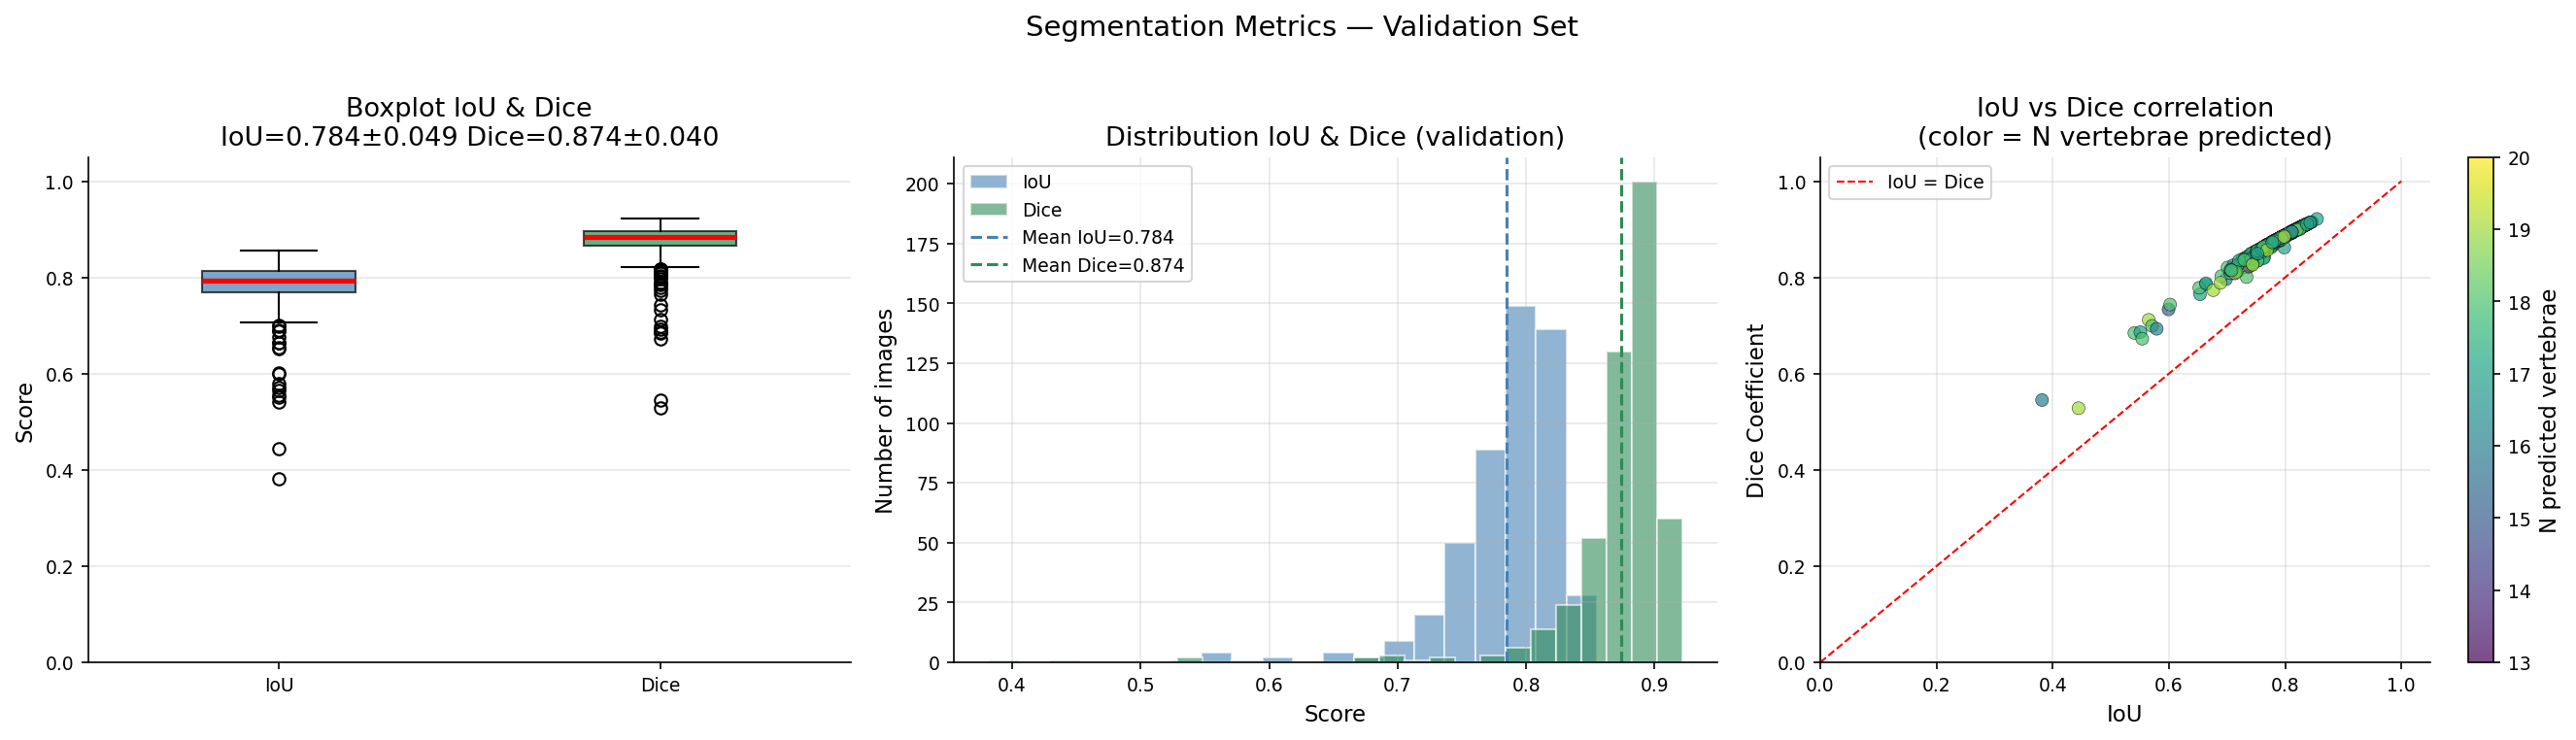

✓ Saved fig_seg_iou_dice.png/.pdf


In [ ]:
iou_arr  = df_metrics['iou'].values
dice_arr = df_metrics['dice'].values

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

bp = axes[0].boxplot([iou_arr, dice_arr], tick_labels=['IoU', 'Dice'],
                     patch_artist=True,
                     medianprops=dict(color='red', linewidth=2.5), widths=0.4)
for patch, color in zip(bp['boxes'], ['steelblue', 'seagreen']):
    patch.set_facecolor(color); patch.set_alpha(0.7)
axes[0].set_ylim(0, 1.05); axes[0].set_ylabel('Score')
axes[0].set_title(f'Boxplot IoU & Dice\n'
                  f'IoU={iou_arr.mean():.3f}±{iou_arr.std():.3f} '
                  f'Dice={dice_arr.mean():.3f}±{dice_arr.std():.3f}')
axes[0].grid(axis='y', alpha=0.3)

axes[1].hist(iou_arr,  bins=20, color='steelblue', alpha=0.6, edgecolor='white', label='IoU')
axes[1].hist(dice_arr, bins=20, color='seagreen',  alpha=0.6, edgecolor='white', label='Dice')
axes[1].axvline(iou_arr.mean(),  color='steelblue', linestyle='--', lw=1.5, label=f'Mean IoU={iou_arr.mean():.3f}')
axes[1].axvline(dice_arr.mean(), color='seagreen',  linestyle='--', lw=1.5, label=f'Mean Dice={dice_arr.mean():.3f}')
axes[1].set_xlabel('Score'); axes[1].set_ylabel('Number of images')
axes[1].set_title('Distribution IoU & Dice (validation)')
axes[1].legend(fontsize=9); axes[1].grid(alpha=0.3)

sc = axes[2].scatter(iou_arr, dice_arr, c=df_metrics['n_pred'].values,
                     cmap='viridis', alpha=0.7, edgecolors='k', linewidths=0.3, s=40)
axes[2].plot([0, 1], [0, 1], 'r--', lw=1, label='IoU = Dice')
plt.colorbar(sc, ax=axes[2], label='N predicted vertebrae')
axes[2].set_xlabel('IoU'); axes[2].set_ylabel('Dice Coefficient')
axes[2].set_title('IoU vs Dice correlation\n(color = N vertebrae predicted)')
axes[2].legend(fontsize=9); axes[2].set_xlim(0, 1.05); axes[2].set_ylim(0, 1.05); axes[2].grid(alpha=0.3)

plt.suptitle('Segmentation Metrics — Validation Set', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(FIGDIR / 'fig_seg_iou_dice.png', dpi=300, bbox_inches='tight')
plt.savefig(FIGDIR / 'fig_seg_iou_dice.pdf', bbox_inches='tight')
plt.show()
print("✓ Saved fig_seg_iou_dice.png/.pdf")

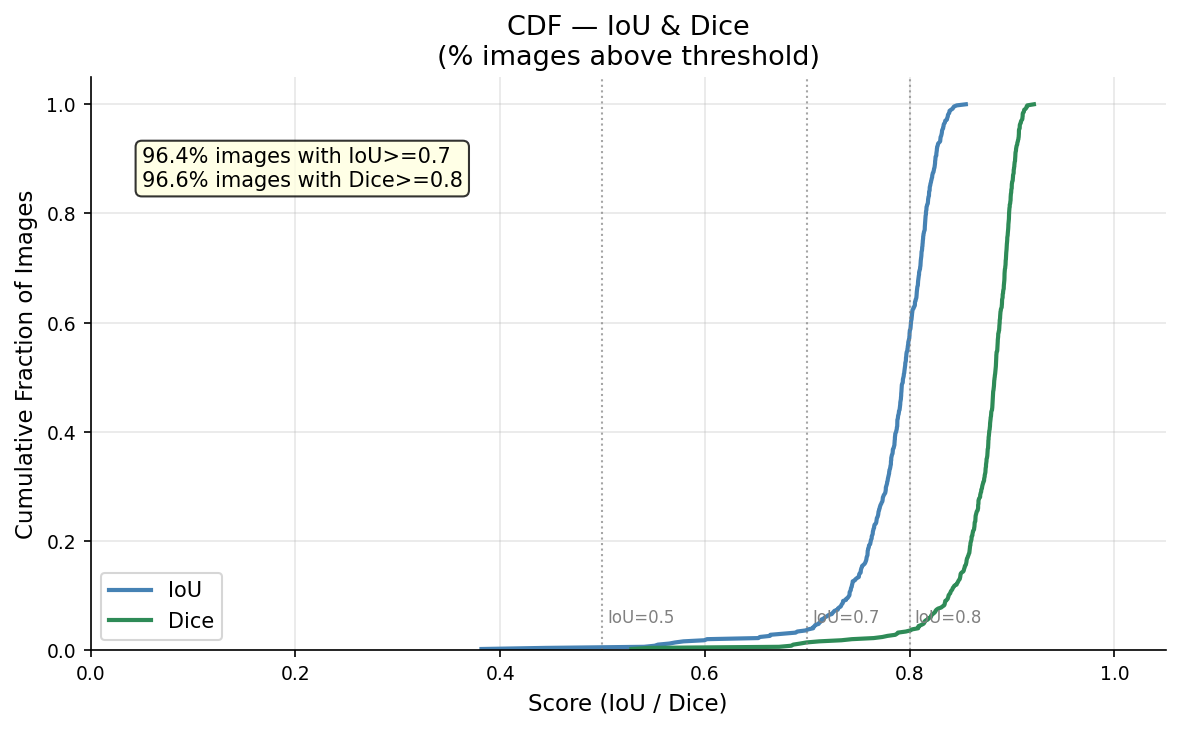

✓ Saved fig_seg_cdf.png/.pdf
  % IoU  >= 0.5 : 99.6%
  % IoU  >= 0.7 : 96.4%
  % Dice >= 0.8 : 96.6%


In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
for arr, label, color in [
    (np.sort(iou_arr),  'IoU',  'steelblue'),
    (np.sort(dice_arr), 'Dice', 'seagreen')
]:
    cdf = np.arange(1, len(arr)+1) / len(arr)
    ax.plot(arr, cdf, lw=2, label=label, color=color)

for threshold, lab in [(0.5, 'IoU=0.5'), (0.7, 'IoU=0.7'), (0.8, 'IoU=0.8')]:
    ax.axvline(threshold, color='gray', linestyle=':', lw=1, alpha=0.7)
    ax.text(threshold + 0.005, 0.05, lab, fontsize=8, color='gray')

ax.set_xlabel('Score (IoU / Dice)'); ax.set_ylabel('Cumulative Fraction of Images')
ax.set_title('CDF — IoU & Dice\n(% images above threshold)')
ax.legend(); ax.grid(alpha=0.3); ax.set_xlim(0, 1.05); ax.set_ylim(0, 1.05)

pct_iou_07  = (iou_arr  >= 0.7).mean() * 100
pct_dice_08 = (dice_arr >= 0.8).mean() * 100
ax.text(0.05, 0.85, f'{pct_iou_07:.1f}% images with IoU>=0.7\n{pct_dice_08:.1f}% images with Dice>=0.8',
        fontsize=10, bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.savefig(FIGDIR / 'fig_seg_cdf.png', dpi=300, bbox_inches='tight')
plt.savefig(FIGDIR / 'fig_seg_cdf.pdf', bbox_inches='tight')
plt.show()
print("✓ Saved fig_seg_cdf.png/.pdf")
print(f"  % IoU  >= 0.5 : {(iou_arr>=0.5).mean()*100:.1f}%")
print(f"  % IoU  >= 0.7 : {(iou_arr>=0.7).mean()*100:.1f}%")
print(f"  % Dice >= 0.8 : {(dice_arr>=0.8).mean()*100:.1f}%")

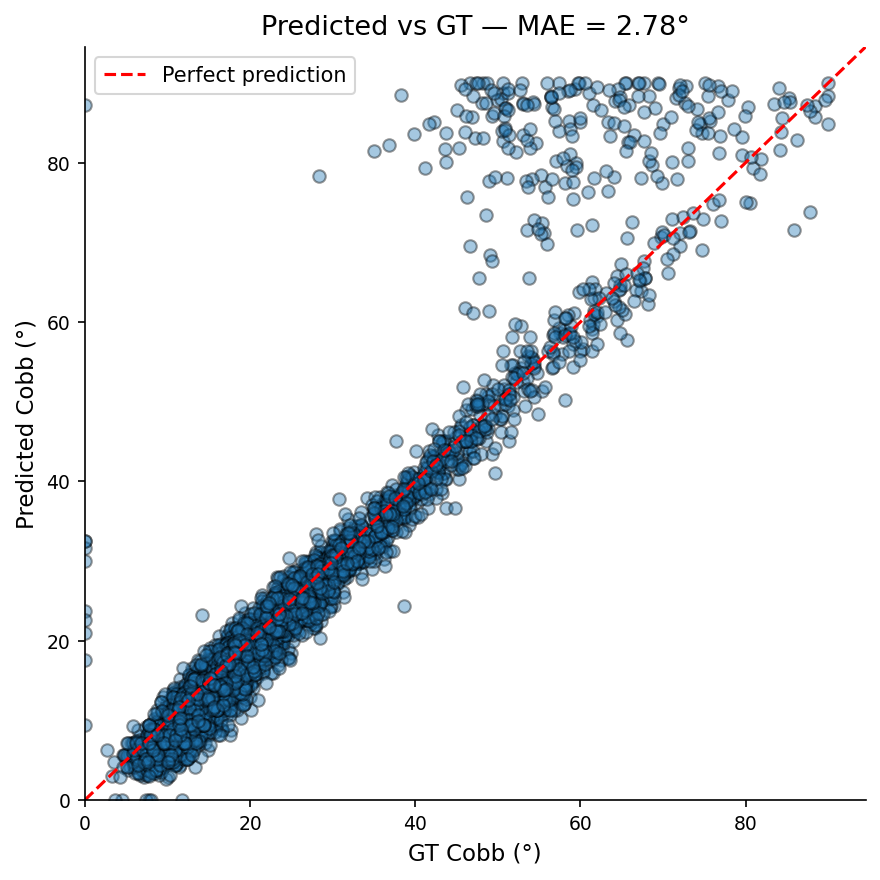

Global MAE (val+test): 2.78°


In [ ]:
all_common = pd.concat([
    df_results.dropna(subset=["cobb", "gt_cobb"])[["cobb", "gt_cobb"]],
    df_test.dropna(subset=["cobb", "gt_cobb"])[["cobb", "gt_cobb"]],
], ignore_index=True)

if len(all_common):
    mae_global = (all_common["cobb"] - all_common["gt_cobb"]).abs().mean()
    lim = float(all_common.max().max()) * 1.05
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(all_common["gt_cobb"], all_common["cobb"], alpha=0.4, edgecolors='k')
    ax.plot([0, lim], [0, lim], "r--", label="Perfect prediction")
    ax.set_xlabel("GT Cobb (°)"); ax.set_ylabel("Predicted Cobb (°)")
    ax.set_title(f"Predicted vs GT — MAE = {mae_global:.2f}°"); ax.legend()
    ax.set_xlim(0, lim); ax.set_ylim(0, lim); plt.tight_layout(); plt.show()
    print(f"Global MAE (val+test): {mae_global:.2f}°")
else:
    print("No usable GT — check cell 25.")

Sensitivity / Specificity par classe :
   Class   TP  FN  FP   TN  Sensitivity  Specificity
    Mild 2239  42 113  993     0.981587     0.897830
Moderate  554 121  60 2652     0.820741     0.977876
  Severe  413  18   8 2948     0.958237     0.997294


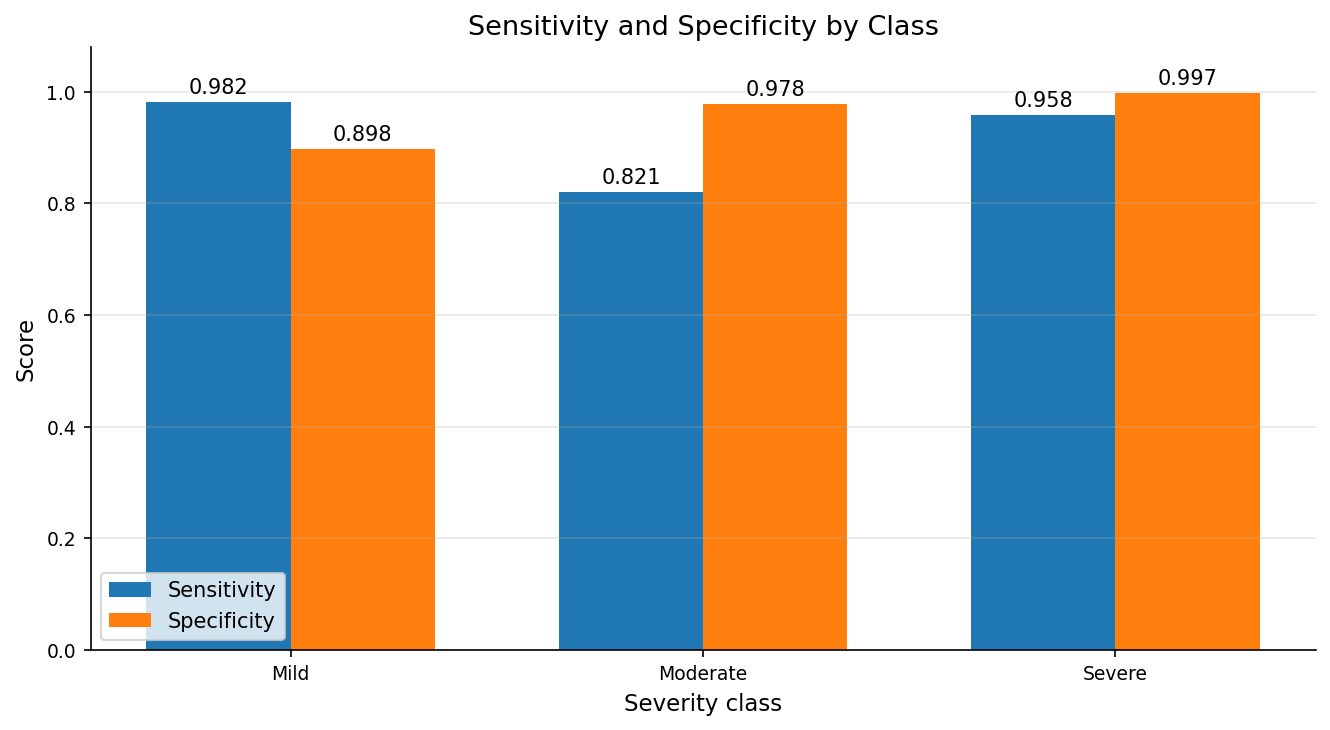

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

labels = ["Mild", "Moderate", "Severe"]
cm = confusion_matrix(y_true, y_pred, labels=labels)

sens_spec_rows = []

for i, c in enumerate(labels):
    TP = cm[i, i]
    FN = cm[i, :].sum() - TP
    FP = cm[:, i].sum() - TP
    TN = cm.sum() - TP - FN - FP

    sensitivity = TP / (TP + FN) if (TP + FN) > 0 else np.nan
    specificity = TN / (TN + FP) if (TN + FP) > 0 else np.nan

    sens_spec_rows.append({
        "Class": c,
        "TP": TP,
        "FN": FN,
        "FP": FP,
        "TN": TN,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
    })

df_sens_spec = pd.DataFrame(sens_spec_rows)

print("Sensitivity / Specificity par classe :")
print(df_sens_spec.to_string(index=False))

# sauvegarde tableau
df_sens_spec_rounded = df_sens_spec.copy()
df_sens_spec_rounded["Sensitivity"] = df_sens_spec_rounded["Sensitivity"].round(4)
df_sens_spec_rounded["Specificity"] = df_sens_spec_rounded["Specificity"].round(4)
df_sens_spec_rounded.to_csv(FIGDIR / "table_sensitivity_specificity.csv", index=False)

# figure
x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, df_sens_spec["Sensitivity"], width, label="Sensitivity", color="#1f77b4")
plt.bar(x + width/2, df_sens_spec["Specificity"], width, label="Specificity", color="#ff7f0e")

for i, v in enumerate(df_sens_spec["Sensitivity"]):
    plt.text(i - width/2, v + 0.015, f"{v:.3f}", ha="center", fontsize=10)

for i, v in enumerate(df_sens_spec["Specificity"]):
    plt.text(i + width/2, v + 0.015, f"{v:.3f}", ha="center", fontsize=10)

plt.xticks(x, labels)
plt.ylim(0, 1.08)
plt.ylabel("Score")
plt.xlabel("Severity class")
plt.title("Sensitivity and Specificity by Class")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(FIGDIR / "fig_sensitivity_specificity.png", dpi=300, bbox_inches="tight")
plt.savefig(FIGDIR / "fig_sensitivity_specificity.pdf", bbox_inches="tight")
plt.show()

                           Task    AUC  Sensitivity_at_clinical_threshold  Specificity_at_clinical_threshold  Clinical_threshold
>=25° (Moderate+Severe vs Mild) 0.9927                             0.8978                             0.9841                  25
   >=40° (Severe vs non-Severe) 0.9990                             0.9582                             0.9975                  40


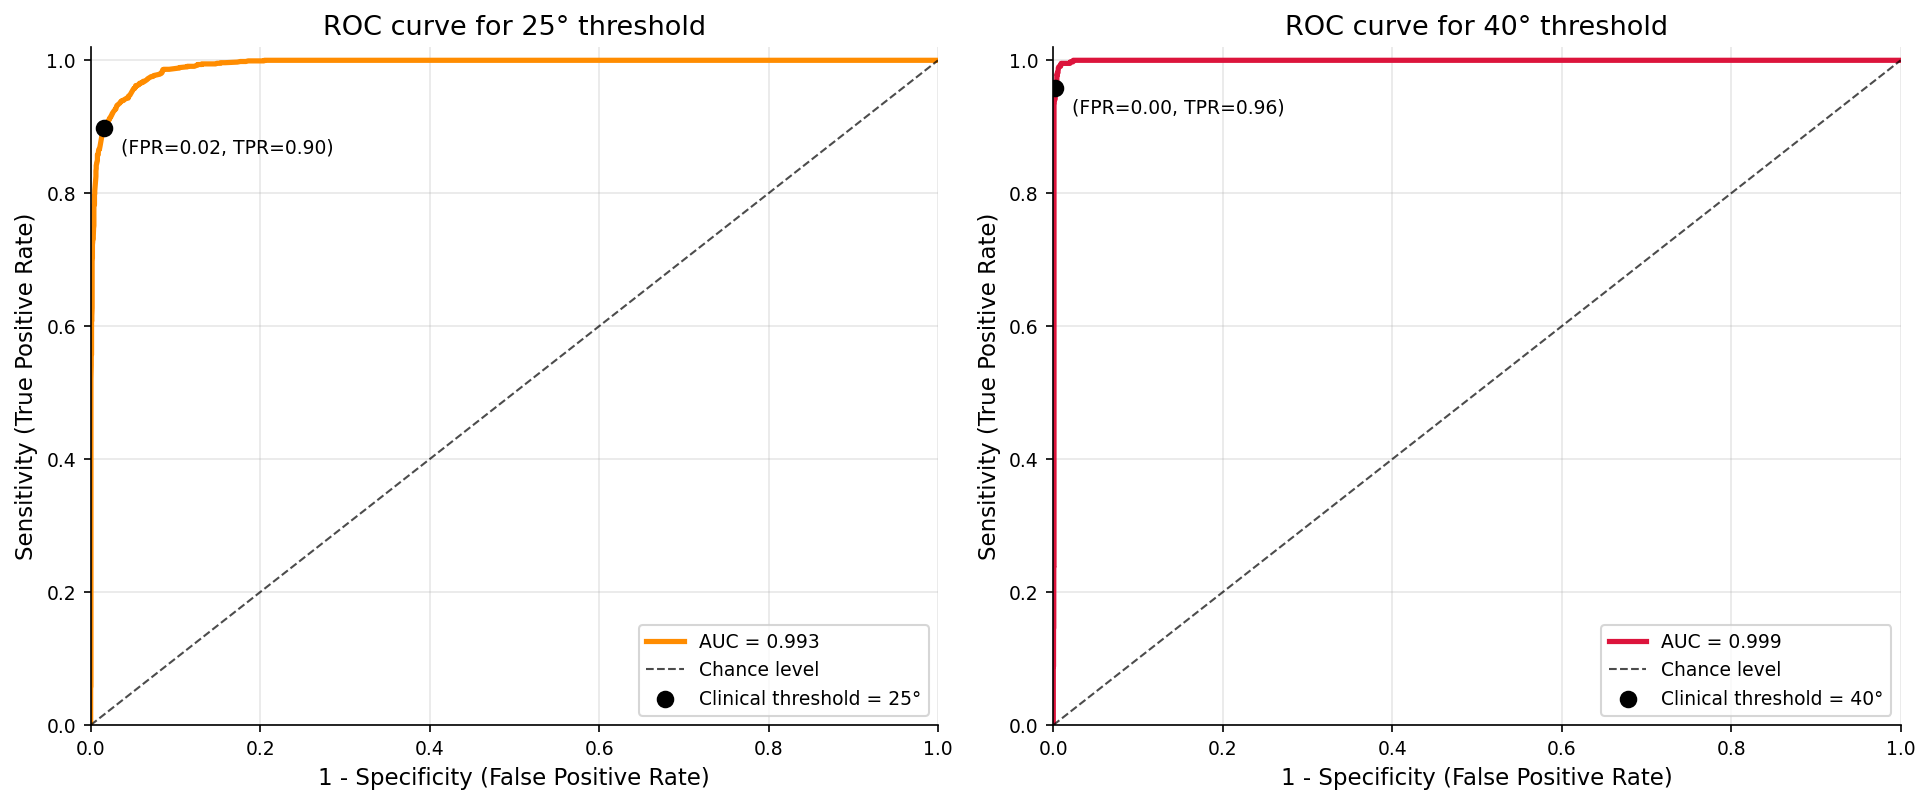

AUC at 25° = 0.9927
Sensitivity at 25° = 0.8978
Specificity at 25° = 0.9841
AUC at 40° = 0.9990
Sensitivity at 40° = 0.9582
Specificity at 40° = 0.9975


In [ ]:
from sklearn.metrics import roc_curve, auc, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

roc_rows = []

# =========================
# 1) ROC pour seuil 25°
# =========================
y_true_25 = (df_test["gt_cobb"] >= 25).astype(int)
y_score_25 = df_test["cobb"].fillna(0).astype(float)

fpr25, tpr25, thr25 = roc_curve(y_true_25, y_score_25)
auc25 = auc(fpr25, tpr25)

# point opératoire réel au seuil clinique 25°
y_pred_25 = (y_score_25 >= 25).astype(int)
cm25 = confusion_matrix(y_true_25, y_pred_25, labels=[0, 1])
tn25, fp25, fn25, tp25 = cm25.ravel()

sens25 = tp25 / (tp25 + fn25) if (tp25 + fn25) > 0 else np.nan
spec25 = tn25 / (tn25 + fp25) if (tn25 + fp25) > 0 else np.nan
fpr_point25 = 1 - spec25
tpr_point25 = sens25

roc_rows.append({
    "Task": ">=25° (Moderate+Severe vs Mild)",
    "AUC": round(auc25, 4),
    "Sensitivity_at_clinical_threshold": round(sens25, 4),
    "Specificity_at_clinical_threshold": round(spec25, 4),
    "Clinical_threshold": 25
})

# =========================
# 2) ROC pour seuil 40°
# =========================
y_true_40 = (df_test["gt_cobb"] >= 40).astype(int)
y_score_40 = df_test["cobb"].fillna(0).astype(float)

fpr40, tpr40, thr40 = roc_curve(y_true_40, y_score_40)
auc40 = auc(fpr40, tpr40)

# point opératoire réel au seuil clinique 40°
y_pred_40 = (y_score_40 >= 40).astype(int)
cm40 = confusion_matrix(y_true_40, y_pred_40, labels=[0, 1])
tn40, fp40, fn40, tp40 = cm40.ravel()

sens40 = tp40 / (tp40 + fn40) if (tp40 + fn40) > 0 else np.nan
spec40 = tn40 / (tn40 + fp40) if (tn40 + fp40) > 0 else np.nan
fpr_point40 = 1 - spec40
tpr_point40 = sens40

roc_rows.append({
    "Task": ">=40° (Severe vs non-Severe)",
    "AUC": round(auc40, 4),
    "Sensitivity_at_clinical_threshold": round(sens40, 4),
    "Specificity_at_clinical_threshold": round(spec40, 4),
    "Clinical_threshold": 40
})

# =========================
# 3) Tableau
# =========================
df_roc_auc = pd.DataFrame(roc_rows)
print(df_roc_auc.to_string(index=False))
df_roc_auc.to_csv(FIGDIR / "table_roc_auc.csv", index=False)

# =========================
# 4) Figure publication-ready
# =========================
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# ----- seuil 25°
axes[0].plot(fpr25, tpr25, color="darkorange", lw=2.5, label=f"AUC = {auc25:.3f}")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, alpha=0.7, label="Chance level")
axes[0].scatter(fpr_point25, tpr_point25, color="black", s=55, zorder=5, label="Clinical threshold = 25°")
axes[0].annotate(
    f"(FPR={fpr_point25:.2f}, TPR={tpr_point25:.2f})",
    (fpr_point25, tpr_point25),
    textcoords="offset points",
    xytext=(8, -12),
    fontsize=9
)
axes[0].set_xlabel("1 - Specificity (False Positive Rate)")
axes[0].set_ylabel("Sensitivity (True Positive Rate)")
axes[0].set_title("ROC curve for 25° threshold")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.02)
axes[0].grid(alpha=0.3)
axes[0].legend(loc="lower right", fontsize=9)

# ----- seuil 40°
axes[1].plot(fpr40, tpr40, color="crimson", lw=2.5, label=f"AUC = {auc40:.3f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, alpha=0.7, label="Chance level")
axes[1].scatter(fpr_point40, tpr_point40, color="black", s=55, zorder=5, label="Clinical threshold = 40°")
axes[1].annotate(
    f"(FPR={fpr_point40:.2f}, TPR={tpr_point40:.2f})",
    (fpr_point40, tpr_point40),
    textcoords="offset points",
    xytext=(8, -12),
    fontsize=9
)
axes[1].set_xlabel("1 - Specificity (False Positive Rate)")
axes[1].set_ylabel("Sensitivity (True Positive Rate)")
axes[1].set_title("ROC curve for 40° threshold")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.02)
axes[1].grid(alpha=0.3)
axes[1].legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig(FIGDIR / "fig_roc_curves_publication.png", dpi=300, bbox_inches="tight")
plt.savefig(FIGDIR / "fig_roc_curves_publication.pdf", bbox_inches="tight")
plt.show()

print(f"AUC at 25° = {auc25:.4f}")
print(f"Sensitivity at 25° = {sens25:.4f}")
print(f"Specificity at 25° = {spec25:.4f}")

print(f"AUC at 40° = {auc40:.4f}")
print(f"Sensitivity at 40° = {sens40:.4f}")
print(f"Specificity at 40° = {spec40:.4f}")

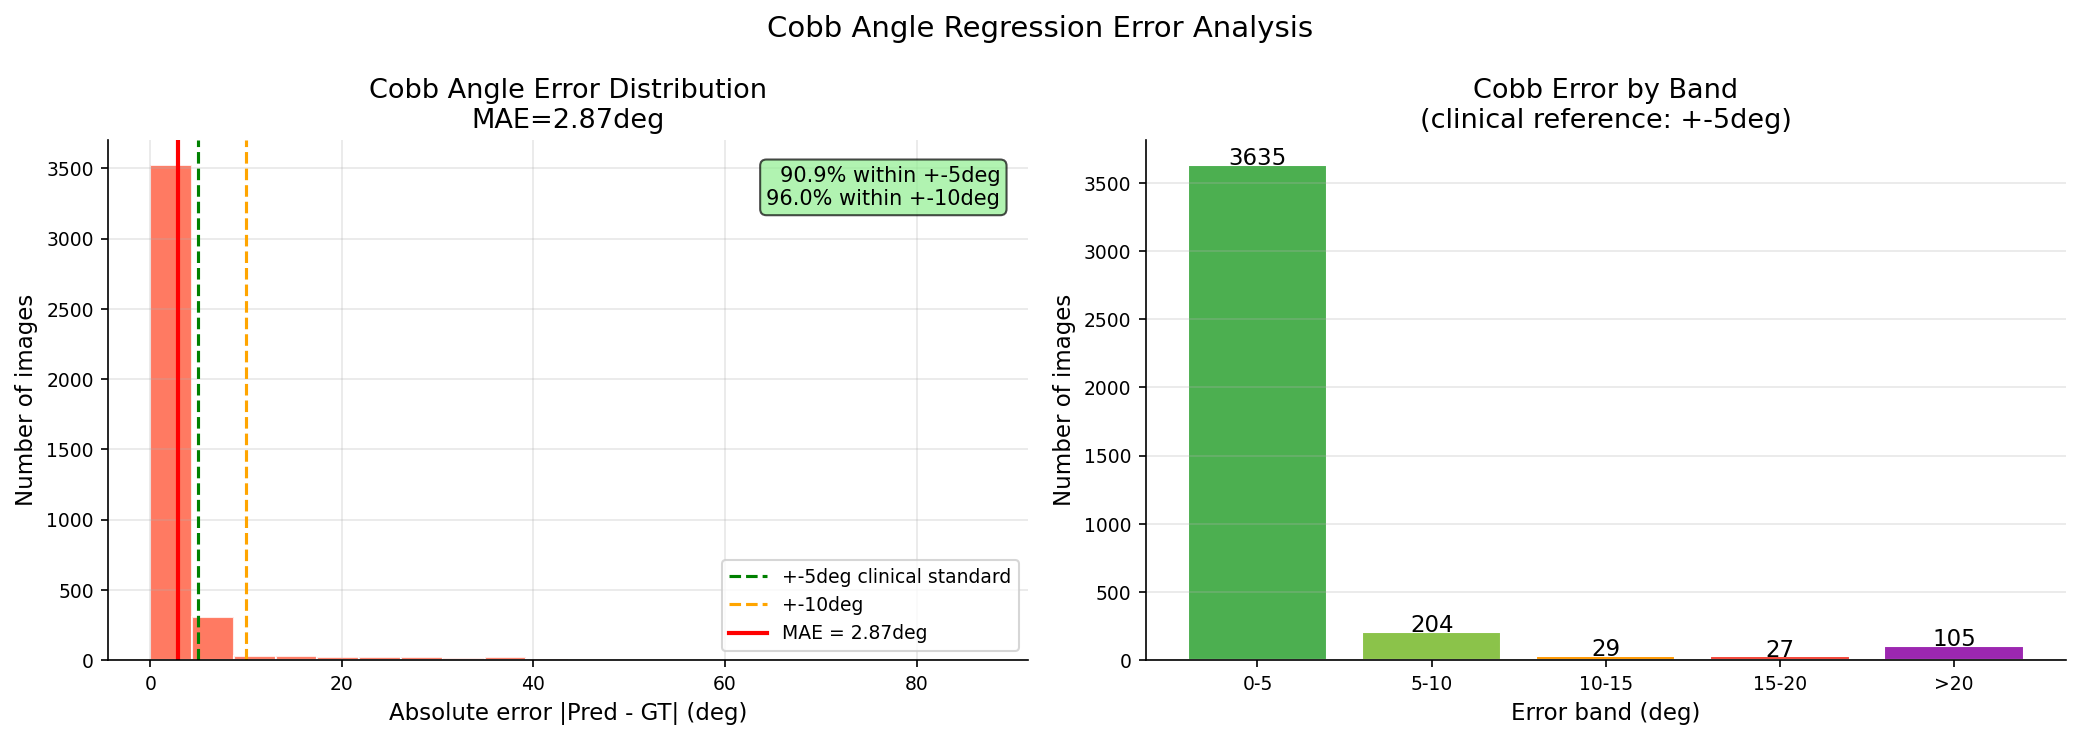

✓ Saved fig_cobb_error_dist.png/.pdf


In [ ]:
if len(common_t) > 0:
    errors = np.abs(pred_arr - gt_arr)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].hist(errors, bins=20, color='tomato', edgecolor='white', alpha=0.85)
    axes[0].axvline(5,  color='green',  linestyle='--', lw=1.5, label='+-5deg clinical standard')
    axes[0].axvline(10, color='orange', linestyle='--', lw=1.5, label='+-10deg')
    axes[0].axvline(mae_test, color='red', linestyle='-', lw=2, label=f'MAE = {mae_test:.2f}deg')
    axes[0].set_xlabel('Absolute error |Pred - GT| (deg)'); axes[0].set_ylabel('Number of images')
    axes[0].set_title(f'Cobb Angle Error Distribution\nMAE={mae_test:.2f}deg')
    axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)
    pct5  = (errors <= 5).mean() * 100
    pct10 = (errors <= 10).mean() * 100
    axes[0].text(0.97, 0.95, f'{pct5:.1f}% within +-5deg\n{pct10:.1f}% within +-10deg',
                 transform=axes[0].transAxes, ha='right', va='top',
                 fontsize=10, bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7))

    bands = ['0-5', '5-10', '10-15', '15-20', '>20']
    thresholds = [0, 5, 10, 15, 20, np.inf]
    counts_err = [((errors >= thresholds[i]) & (errors < thresholds[i+1])).sum() for i in range(5)]
    bar_colors = ['#4caf50', '#8bc34a', '#ff9800', '#f44336', '#9c27b0']
    bars = axes[1].bar(bands, counts_err, color=bar_colors, edgecolor='white')
    for b, c in zip(bars, counts_err):
        axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.3, str(c), ha='center', fontsize=11)
    axes[1].set_xlabel('Error band (deg)'); axes[1].set_ylabel('Number of images')
    axes[1].set_title('Cobb Error by Band\n(clinical reference: +-5deg)')
    axes[1].grid(axis='y', alpha=0.3)

    plt.suptitle('Cobb Angle Regression Error Analysis', fontsize=14)
    plt.tight_layout()
    plt.savefig(FIGDIR / 'fig_cobb_error_dist.png', dpi=300, bbox_inches='tight')
    plt.savefig(FIGDIR / 'fig_cobb_error_dist.pdf', bbox_inches='tight')
    plt.show()
    print("✓ Saved fig_cobb_error_dist.png/.pdf")

Table 1:
 Split  N images  N annotations  Categories
Train     16000         273450           1
 Test      4000          68815           1 

Table 2:
 Metric   Mean    Std    Min    Max
   IoU 0.7845 0.0490 0.3818 0.8549
  Dice 0.8740 0.0396 0.5282 0.9214 

  ✓ Saved fig_boxplot_iou_dice.png / .pdf


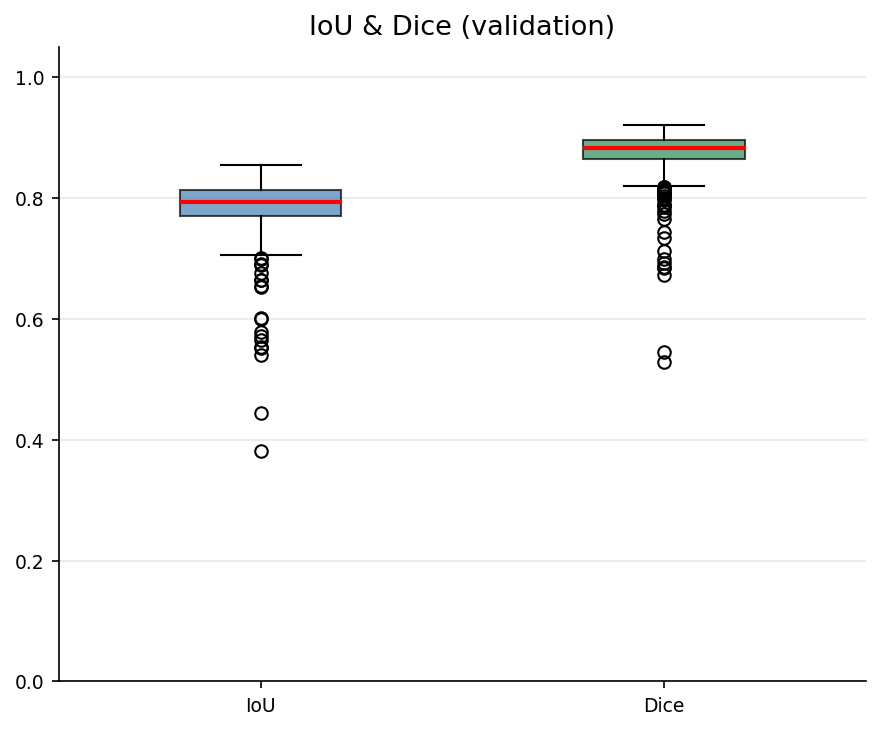

  ✓ Saved fig_severity.png / .pdf


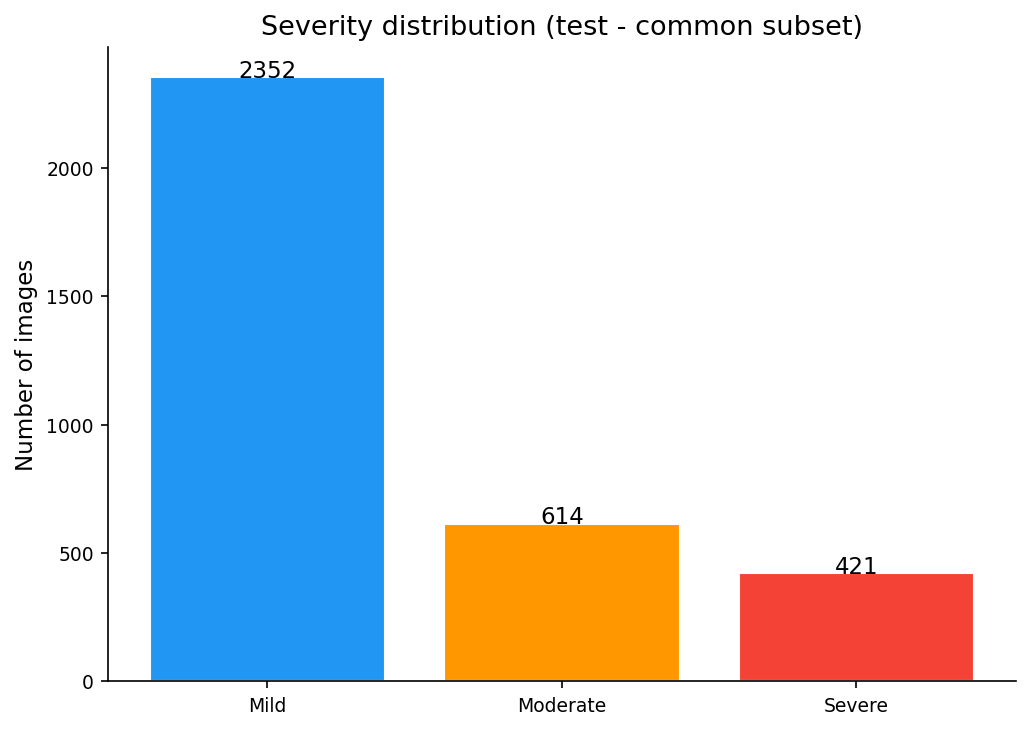

Table 3:
                Metric   Value
       Mean IoU (val)  0.7845
      Mean Dice (val)  0.8740
 MAE Cobb vs GT (deg)  2.7800
 Mean Cobb test (deg) 22.8700
Severity accuracy (%) 94.6600


In [ ]:
df_dataset = pd.DataFrame({
    "Split": ["Train", "Test"],
    "N images": [len(images_by_id), len(test_images_by_id)],
    "N annotations": [len(train_data["annotations"]), len(test_data["annotations"])],
    "Categories": [1, 1],
})
df_dataset.to_csv(FIG_DIR / "table1_dataset.csv", index=False)
print("Table 1:\n", df_dataset.to_string(index=False), "\n")

iou_arr, dice_arr = df_metrics["iou"].values, df_metrics["dice"].values

df_seg = pd.DataFrame({
    "Metric": ["IoU", "Dice"],
    "Mean": [round(iou_arr.mean(), 4), round(dice_arr.mean(), 4)],
    "Std": [round(iou_arr.std(), 4), round(dice_arr.std(), 4)],
    "Min": [round(iou_arr.min(), 4), round(dice_arr.min(), 4)],
    "Max": [round(iou_arr.max(), 4), round(dice_arr.max(), 4)],
})
df_seg.to_csv(FIG_DIR / "table2_segmentation.csv", index=False)
print("Table 2:\n", df_seg.to_string(index=False), "\n")

fig, ax = plt.subplots(figsize=(6, 5))
bp = ax.boxplot([iou_arr, dice_arr], tick_labels=["IoU", "Dice"], patch_artist=True,
                medianprops=dict(color="red", lw=2), widths=0.4)
for patch, c in zip(bp["boxes"], ["steelblue", "seagreen"]):
    patch.set_facecolor(c); patch.set_alpha(0.7)
ax.set_ylim(0, 1.05); ax.set_title("IoU & Dice (validation)"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); save_fig("fig_boxplot_iou_dice"); plt.show()

#----- 3 CLASSES -----
LABELS = ["Mild", "Moderate", "Severe"]
COLORS = ["#2196f3", "#ff9800", "#f44336"]

#  CORRECTION : Utiliser common_sev au lieu de df_test pour la cohérence
counts = [int((common_sev["severity"] == l).sum()) for l in LABELS]

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(LABELS, counts, color=COLORS, edgecolor="white")
for b, c in zip(bars, counts):
    ax.text(b.get_x() + b.get_width()/2, b.get_height()+0.3, str(c), ha="center")
ax.set_ylabel("Number of images"); ax.set_title("Severity distribution (test - common subset)")
plt.tight_layout(); save_fig("fig_severity"); plt.show()

mae_cobb = (all_common["cobb"] - all_common["gt_cobb"]).abs().mean() if len(all_common) else float("nan")

df_summary = pd.DataFrame([
    ("Mean IoU (val)", round(iou_arr.mean(), 4)),
    ("Mean Dice (val)", round(dice_arr.mean(), 4)),
    ("MAE Cobb vs GT (deg)", round(mae_cobb, 2) if not np.isnan(mae_cobb) else "N/A"),
    ("Mean Cobb test (deg)", round(df_test["cobb"].dropna().mean(), 2)),
    ("Severity accuracy (%)", round(acc * 100, 2)),
], columns=["Metric", "Value"])

df_summary.to_csv(FIG_DIR / "table3_summary.csv", index=False)
print("Table 3:\n", df_summary.to_string(index=False))

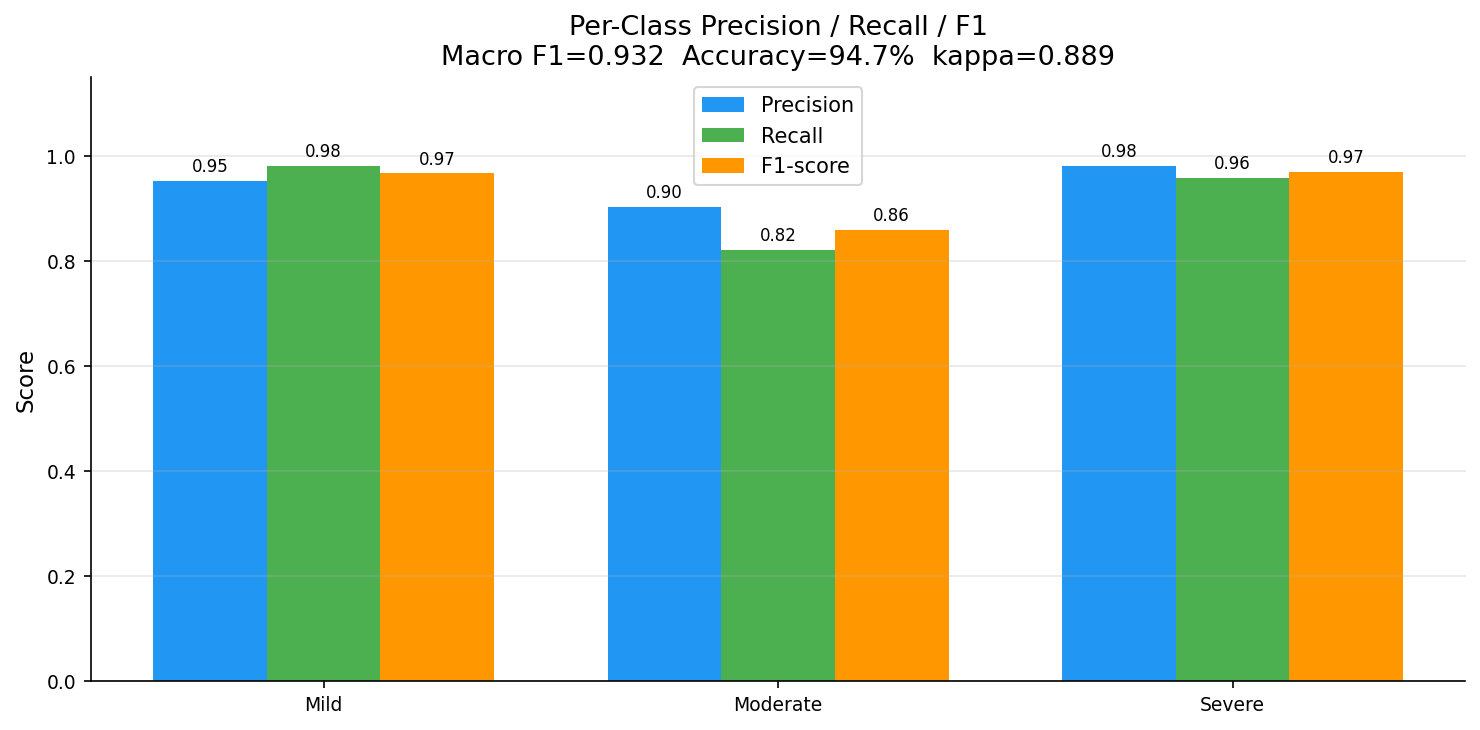

✓ Saved fig_perclass_metrics.png/.pdf

=== Per-class metrics ===
   Class  Precision  Recall  F1-score  Support
    Mild     0.9520  0.9816    0.9665     2281
Moderate     0.9023  0.8207    0.8596      675
  Severe     0.9810  0.9582    0.9695      431


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

LABELS = ["Mild", "Moderate", "Severe"]   # cohérence 3 classes

if len(y_true) > 0:
    precisions = precision_score(y_true, y_pred, labels=LABELS, average=None, zero_division=0)
    recalls    = recall_score(y_true, y_pred,    labels=LABELS, average=None, zero_division=0)
    f1s        = f1_score(y_true, y_pred,        labels=LABELS, average=None, zero_division=0)

    x = np.arange(len(LABELS)); width = 0.25
    colors = ['#2196f3', '#4caf50', '#ff9800']   # Precision / Recall / F1
    fig, ax = plt.subplots(figsize=(10, 5))
    b1 = ax.bar(x - width, precisions, width, label='Precision', color=colors[0])
    b2 = ax.bar(x,         recalls,    width, label='Recall',    color=colors[1])
    b3 = ax.bar(x + width, f1s,        width, label='F1-score',  color=colors[2])
    for bars in [b1, b2, b3]:
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.01, f'{h:.2f}',
                    ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(LABELS); ax.set_ylim(0, 1.15); ax.set_ylabel('Score')
    ax.set_title(f'Per-Class Precision / Recall / F1\n'
                 f'Macro F1={macro_f1:.3f}  Accuracy={acc*100:.1f}%  kappa={kappa:.3f}')
    ax.legend(); ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIGDIR / 'fig_perclass_metrics.png', dpi=300, bbox_inches='tight')
    plt.savefig(FIGDIR / 'fig_perclass_metrics.pdf', bbox_inches='tight')
    plt.show()
    print("✓ Saved fig_perclass_metrics.png/.pdf")

    df_perclass = pd.DataFrame({
        'Class': LABELS,
        'Precision': np.round(precisions, 4),
        'Recall':    np.round(recalls, 4),
        'F1-score':  np.round(f1s, 4),
        'Support':   [y_true.count(l) for l in LABELS]
    })
    print("\n=== Per-class metrics ===")
    print(df_perclass.to_string(index=False))
    df_perclass.to_csv(FIGDIR / 'table_perclass_metrics.csv', index=False)

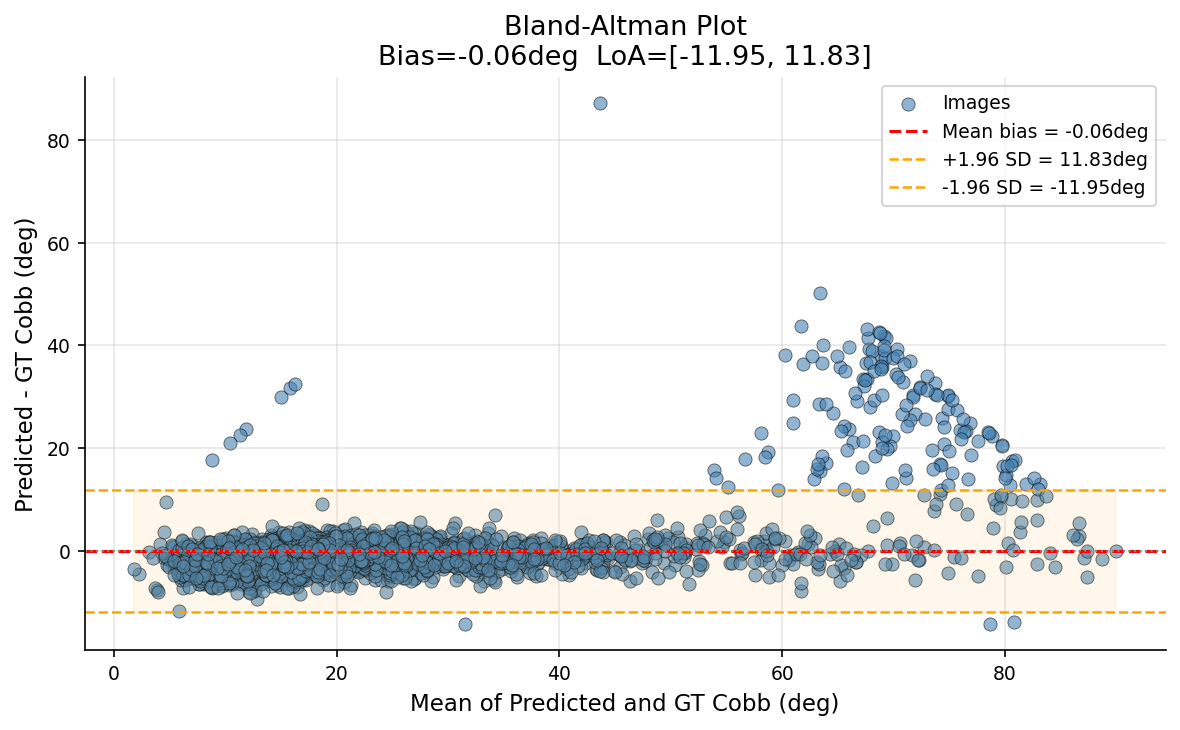

✓ Bland-Altman: bias=-0.06deg LoA=[-11.95, 11.83]


In [ ]:
if len(common_t) > 0:
    mean_vals = (pred_arr + gt_arr) / 2
    diff_vals = pred_arr - gt_arr
    mean_diff = diff_vals.mean(); std_diff = diff_vals.std()
    loa_upper = mean_diff + 1.96 * std_diff
    loa_lower = mean_diff - 1.96 * std_diff

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(mean_vals, diff_vals, alpha=0.6, edgecolors='k', linewidths=0.4,
               s=40, color='steelblue', label='Images')
    ax.axhline(mean_diff, color='red',    linestyle='--', lw=1.5, label=f'Mean bias = {mean_diff:.2f}deg')
    ax.axhline(loa_upper, color='orange', linestyle='--', lw=1.2, label=f'+1.96 SD = {loa_upper:.2f}deg')
    ax.axhline(loa_lower, color='orange', linestyle='--', lw=1.2, label=f'-1.96 SD = {loa_lower:.2f}deg')
    ax.axhline(0, color='gray', linestyle=':', lw=1)
    ax.fill_between([mean_vals.min(), mean_vals.max()], loa_lower, loa_upper, alpha=0.08, color='orange')
    ax.set_xlabel('Mean of Predicted and GT Cobb (deg)'); ax.set_ylabel('Predicted - GT Cobb (deg)')
    ax.set_title(f'Bland-Altman Plot\nBias={mean_diff:.2f}deg  LoA=[{loa_lower:.2f}, {loa_upper:.2f}]')
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIGDIR / 'fig_bland_altman.png', dpi=300, bbox_inches='tight')
    plt.savefig(FIGDIR / 'fig_bland_altman.pdf', bbox_inches='tight')
    plt.show()
    print(f"✓ Bland-Altman: bias={mean_diff:.2f}deg LoA=[{loa_lower:.2f}, {loa_upper:.2f}]")

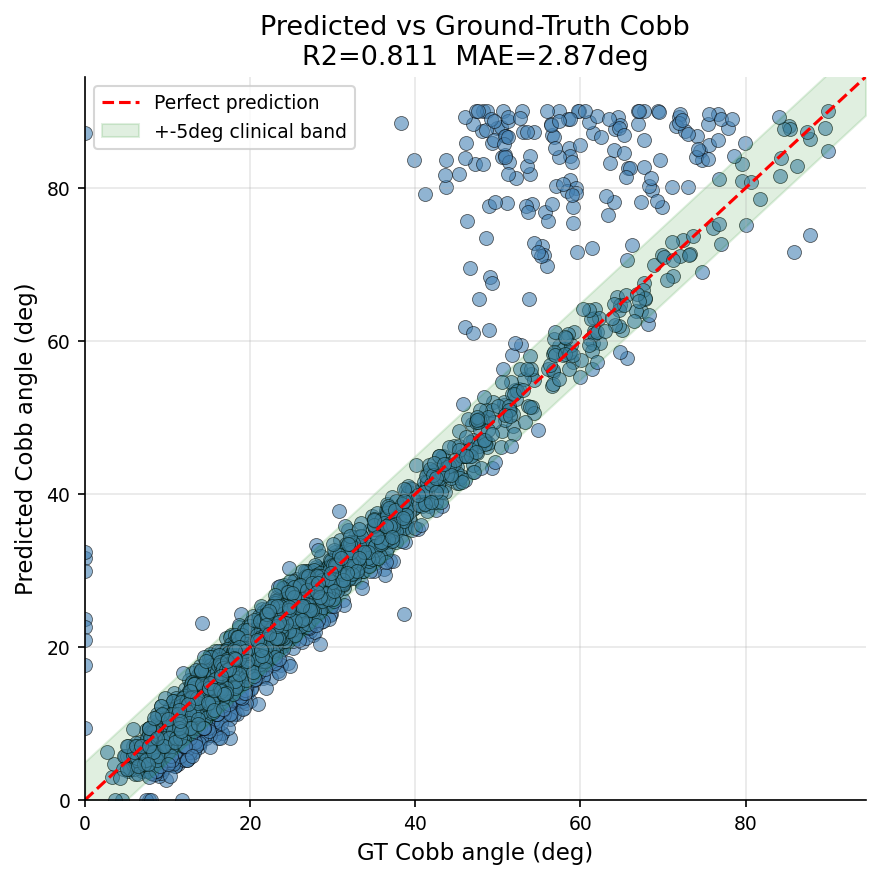

In [ ]:
if len(common_t) > 0:
    lim = max(pred_arr.max(), gt_arr.max()) * 1.05
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(gt_arr, pred_arr, alpha=0.6, edgecolors='k', linewidths=0.4, s=45, color='steelblue')
    ax.plot([0, lim], [0, lim], 'r--', lw=1.5, label='Perfect prediction')
    ax.fill_between([0, lim], [0-5, lim-5], [0+5, lim+5], alpha=0.12, color='green', label='+-5deg clinical band')
    ax.set_xlabel('GT Cobb angle (deg)'); ax.set_ylabel('Predicted Cobb angle (deg)')
    ax.set_title(f'Predicted vs Ground-Truth Cobb\nR2={r2_test:.3f}  MAE={mae_test:.2f}deg')
    ax.legend(fontsize=9); ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIGDIR / 'fig_scatter_cobb.png', dpi=300, bbox_inches='tight')
    plt.savefig(FIGDIR / 'fig_scatter_cobb.pdf', bbox_inches='tight')
    plt.show()

In [ ]:
from pathlib import Path
FIGDIR = Path('/content/thesis_figures')
FIGDIR.mkdir(exist_ok=True)

def save_fig(name, dpi=300):
    plt.savefig(FIGDIR / f'{name}.png', dpi=dpi, bbox_inches='tight')
    plt.savefig(FIGDIR / f'{name}.pdf', bbox_inches='tight')
    print(f"  ✓ Saved {name}.png / .pdf")

plt.rcParams.update({
    'figure.dpi': 150, 'font.family': 'DejaVu Sans',
    'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11,
    'legend.fontsize': 10, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
})
print("Export config ready ->", FIGDIR)

Export config ready -> /content/thesis_figures


  ✓ Saved fig1_learning_curve.png / .pdf


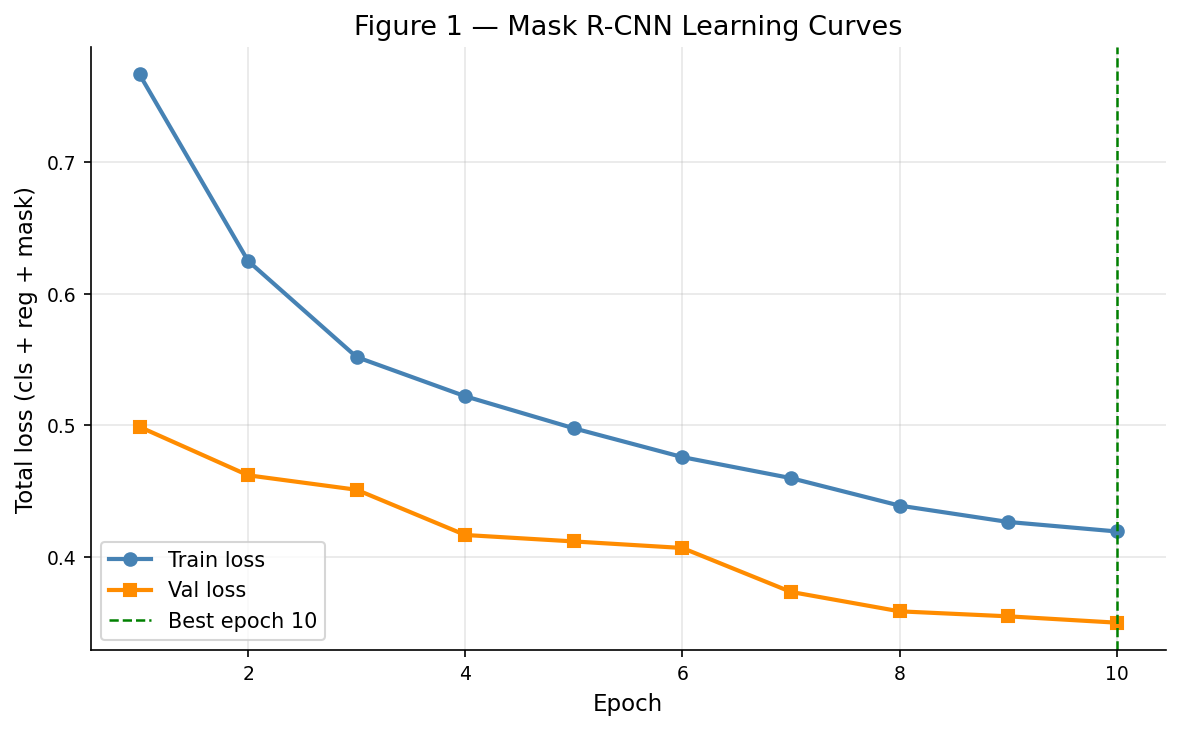

Best epoch: 10 | Min val loss: 0.3501


In [ ]:
epochs = list(range(1, len(train_loss_history) + 1))
best_ep = int(np.argmin(val_loss_history)) + 1

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(epochs, train_loss_history, marker='o', label='Train loss', color='steelblue', linewidth=2)
ax.plot(epochs, val_loss_history,   marker='s', label='Val loss',   color='darkorange', linewidth=2)
ax.axvline(best_ep, color='green', linestyle='--', linewidth=1.2, label=f'Best epoch {best_ep}')
ax.set_xlabel('Epoch'); ax.set_ylabel('Total loss (cls + reg + mask)')
ax.set_title('Figure 1 — Mask R-CNN Learning Curves')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('fig1_learning_curve')
plt.show()
print(f"Best epoch: {best_ep} | Min val loss: {min(val_loss_history):.4f}")

  ✓ Saved fig2_boxplot_iou_dice.png / .pdf


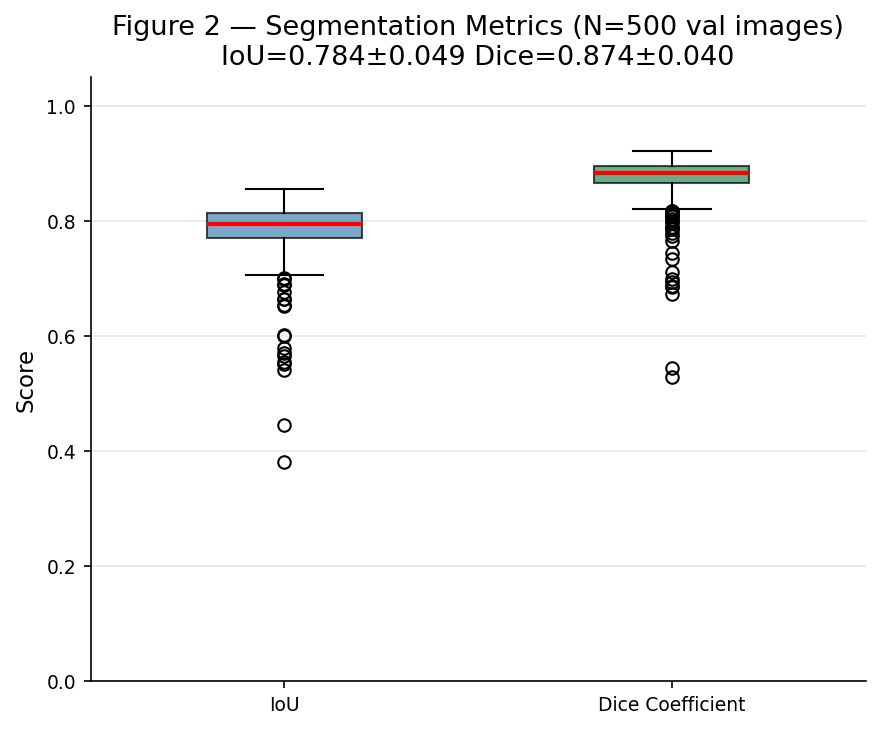

In [ ]:
iou_arr  = df_metrics['iou'].values
dice_arr = df_metrics['dice'].values

fig, ax = plt.subplots(figsize=(6, 5))
bp = ax.boxplot([iou_arr, dice_arr], tick_labels=['IoU', 'Dice Coefficient'], patch_artist=True,
                medianprops=dict(color='red', linewidth=2), widths=0.4)
for patch, c in zip(bp['boxes'], ['steelblue', 'seagreen']):
    patch.set_facecolor(c); patch.set_alpha(0.7)
ax.set_ylim(0, 1.05)
ax.set_title(f'Figure 2 — Segmentation Metrics (N={len(iou_arr)} val images)\n'
             f'IoU={iou_arr.mean():.3f}±{iou_arr.std():.3f} '
             f'Dice={dice_arr.mean():.3f}±{dice_arr.std():.3f}')
ax.set_ylabel('Score'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
save_fig('fig2_boxplot_iou_dice')
plt.show()

In [ ]:
import os
import zipfile
from datetime import datetime
from pathlib import Path

FIG_DIR = Path("/content/thesis_figures")
RAD_DIR = Path("/content/radiographies")
zip_name = Path("/content") / f"chapter_results_{datetime.now().strftime('%Y%m%d_%H%M%S')}.zip"

allowed_ext = {".png", ".jpg", ".jpeg", ".pdf", ".csv", ".xlsx", ".xls"}

folders_to_zip = [FIG_DIR, RAD_DIR]
files_to_add = []

for folder in folders_to_zip:
    if folder.exists():
        for root, dirs, files in os.walk(folder):
            dirs[:] = [d for d in dirs if d not in (".git", "__pycache__", ".ipynb_checkpoints")]
            for f in files:
                if Path(f).suffix.lower() in allowed_ext:
                    files_to_add.append(Path(root) / f)

files_to_add = sorted(set(files_to_add))

if not files_to_add:
    print("Aucun fichier trouvé.")
else:
    with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zf:
        for file_path in files_to_add:
            arcname = file_path.name
            zf.write(file_path, arcname=arcname)

    print(f"ZIP créé avec {len(files_to_add)} fichiers : {zip_name}")

    try:
        from google.colab import files
        files.download(str(zip_name))
    except Exception:
        print("Téléchargement automatique non disponible. Le fichier ZIP est prêt.")

ZIP créé avec 30 fichiers : /content/chapter_results_20260707_180847.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import zipfile
from datetime import datetime
from pathlib import Path
from PIL import Image  # Pour convertir les images en PDF

FIG_DIR = Path("/content/thesis_figures")
RAD_DIR = Path("/content/radiographies")
zip_name = Path("/content") / f"chapter_results_{datetime.now().strftime('%Y%m%d_%H%M%S')}.zip"

allowed_ext = {".png", ".jpg", ".jpeg", ".pdf"}  # On garde PDF et images
folders_to_zip = [FIG_DIR, RAD_DIR]
files_to_add = []

# Parcours des dossiers
for folder in folders_to_zip:
    if folder.exists():
        for root, dirs, files in os.walk(folder):
            dirs[:] = [d for d in dirs if d not in (".git", "__pycache__", ".ipynb_checkpoints")]
            for f in files:
                if Path(f).suffix.lower() in allowed_ext:
                    files_to_add.append(Path(root) / f)

files_to_add = sorted(set(files_to_add))

if not files_to_add:
    print("Aucun fichier trouvé.")
else:
    with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zf:
        for file_path in files_to_add:
            ext = file_path.suffix.lower()
            if ext in {".png", ".jpg", ".jpeg"}:
                # Conversion en PDF
                img = Image.open(file_path).convert("RGB")
                pdf_path = file_path.with_suffix(".pdf")
                img.save(pdf_path)
                arcname = pdf_path.name
                zf.write(pdf_path, arcname=arcname)
            else:
                # Déjà en PDF → on ajoute directement
                arcname = file_path.name
                zf.write(file_path, arcname=arcname)

    print(f"ZIP créé avec {len(files_to_add)} fichiers convertis en PDF : {zip_name}")

    try:
        from google.colab import files
        files.download(str(zip_name))
    except Exception:
        print("Téléchargement automatique non disponible. Le fichier ZIP est prêt.")

/usr/lib/python3.12/zipfile/__init__.py:1624: UserWarning: Duplicate name: 'fig1_learning_curve.pdf'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.12/zipfile/__init__.py:1624: UserWarning: Duplicate name: 'fig2_boxplot_iou_dice.pdf'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.12/zipfile/__init__.py:1624: UserWarning: Duplicate name: 'fig_bland_altman.pdf'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.12/zipfile/__init__.py:1624: UserWarning: Duplicate name: 'fig_boxplot_iou_dice.pdf'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.12/zipfile/__init__.py:1624: UserWarning: Duplicate name: 'fig_cobb_error_dist.pdf'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.12/zipfile/__init__.py:1624: UserWarning: Duplicate name: 'fig_perclass_metrics.pdf'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.12/zipfile

ZIP créé avec 24 fichiers convertis en PDF : /content/chapter_results_20260707_184732.zip


/usr/lib/python3.12/zipfile/__init__.py:1624: UserWarning: Duplicate name: 'fig_severity.pdf'
  return self._open_to_write(zinfo, force_zip64=force_zip64)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>